Step 1 — loaded application_train: (307511, 122)
Step 2 — after ratio features: (307511, 138)
Step 3 — after peer-group features: (307511, 201)
Step 4 — dropped 48 columns. Shape: (307511, 153)
Step 5 — added 29 missing flags. Shape: (307511, 182)
Step 6 — previous_application summary: (338857, 86)
Step 7 — bureau summary: (305811, 109)
Step 8 — installments summary: (339587, 22)
Step 9 — credit card summary: (103558, 23)
Step 10 — POS_CASH summary: (337252, 16)
  previous_application: (338857, 86), duplicate customers = 0
  bureau: (305811, 109), duplicate customers = 0
  installments: (339587, 22), duplicate customers = 0
  credit_card: (103558, 23), duplicate customers = 0
  pos_cash: (337252, 16), duplicate customers = 0
Step 11 — merged everything: (307511, 433) (rows unchanged: 307511)
Step 11 — filled 54 count/sum columns with 0
FINAL table: (307511, 438)  (features = 436)
Step 12 — train (246008, 436), test (61503, 436)
Step 13 — 423 numeric and 13 categorical columns
Step 14 —

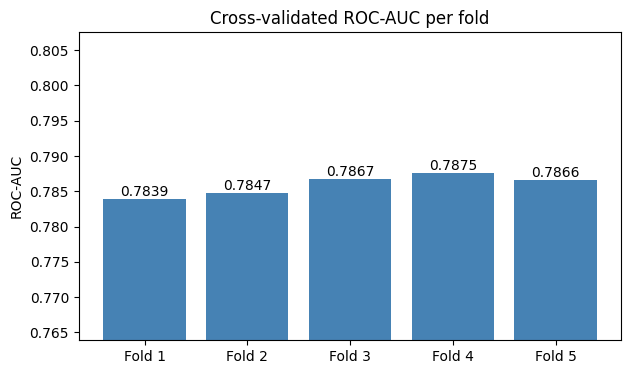


Step 16 — training 5 models with 844 trees each
  finished seed 42
  finished seed 10
  finished seed 2018
  finished seed 38
  finished seed 28

FINAL TEST ROC-AUC: 0.7911
FINAL TEST PR-AUC : 0.2925

Step 17 — best threshold on cross-validation predictions: 0.5


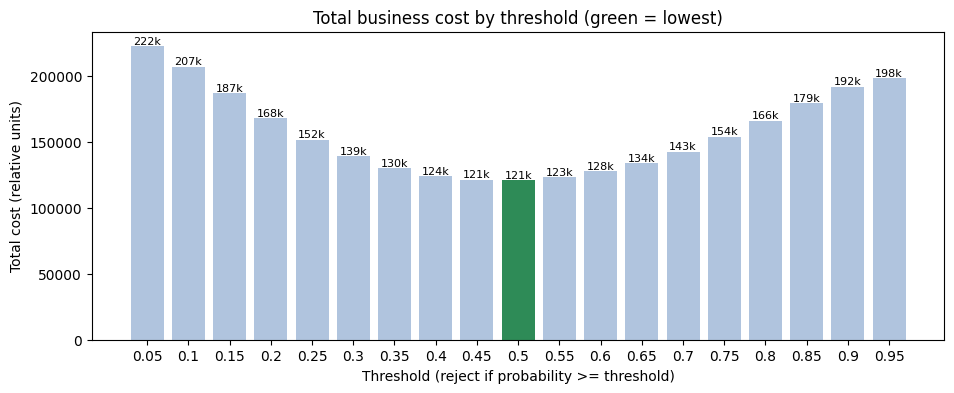

TEST at threshold 0.5: missed defaulters=1604, rejected good customers=13280
  model cost           = 29320
  approve-everyone cost= 49650
  reject-everyone cost = 56538

Step 18 — top 20 features:
EXT_SOURCES_MEAN                                           0.051912
EXT_SOURCES_MIN                                            0.017813
EXT_SOURCES_MAX                                            0.016952
CODE_GENDER_NAME_EDUCATION_TYPE_MEAN_EXT_SOURCE_2          0.011326
INST_DAYS_LATE_MEAN_1Y                                     0.008277
CODE_GENDER_REG_CITY_NOT_WORK_CITY_MEAN_DAYS_ID_PUBLISH    0.007165
OVER_FINANCING_RATIO                                       0.006983
OCCUPATION_TYPE_MEAN_EXT_SOURCE_1                          0.006650
NAME_EDUCATION_TYPE_OCCUPATION_TYPE_MEAN_EXT_SOURCE_2      0.006470
INST_LATE_RATE                                             0.006450
CODE_GENDER_NAME_EDUCATION_TYPE_MEAN_EXT_SOURCE_1          0.006401
PREV_REFUSED_RATIO                                    

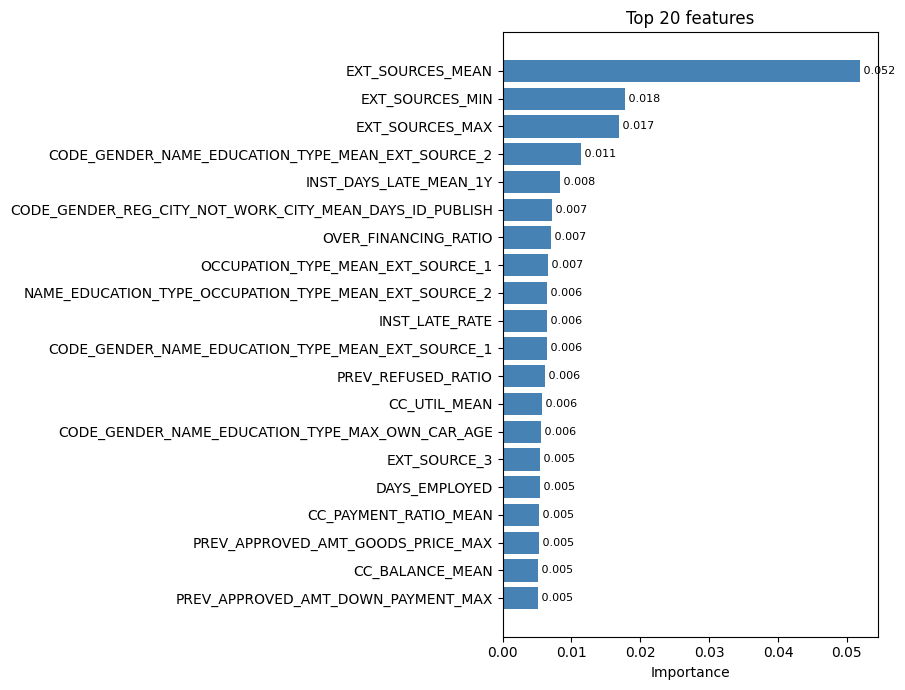

In [ ]:
"""
Home Credit Default Risk — Easy-to-Read Version
==================================================

GOAL
  Predict which customers will fail to repay a loan (TARGET = 1).

THE BIG IDEA (read this first)
  application_train.csv has ONE row per customer.
  The six other files have MANY rows per customer (one row per past loan,
  per month, or per payment). You cannot attach many rows to one row, so:
      (a) SUMMARIZE each other file down to one row per customer
      (b) MERGE that summary onto application_train (it adds new columns)
  Only after every file has been merged do we split the data and train.

WORDS USED IN THIS FILE
  customer ID   SK_ID_CURR. The column that links every file together.
  summarize     Turn many rows into one row, e.g. "average", "maximum",
                "count". Also called "aggregate" or "groupby".
  merge         Add columns to a table by matching on the customer ID.
  NaN           A missing value.
  imputer       A tool that fills in missing values.
  flag          A 0/1 column that says "yes/no", e.g. HAS_CHILDREN.
  rate          The average of a 0/1 flag. 0.30 means "30% of the time".
  fold          One round of cross-validation (train on part, test on the rest).
  leakage       Accidentally letting the model peek at answers it should not
                see, which makes the score look better than it really is.

THE ORDER
   1. Load application_train, fix the 365243 placeholder
   2. Add ratio features (credit/income, EXT_SOURCE averages, ...)
   3. Add "peer group" features (how does this customer compare to similar people?)
   4. Drop columns that are mostly empty or constant
   5. Add "was this value missing?" flags
   6. previous_application   -> 1 row per customer
   7. bureau + bureau_balance -> 1 row per customer
   8. installments_payments  -> 1 row per customer
   9. credit_card_balance    -> 1 row per customer
  10. POS_CASH_balance       -> 1 row per customer
  11. Merge everything, check nothing was duplicated, fill the gaps
  12. Train/test split (the test set is locked away from now on)
  13. Preprocessing recipe (learned only from training rows)
  14. Model settings, including scale_pos_weight
  15. 5-fold cross-validation on the TRAIN part only
  16. Final model: 5 seeds averaged, scored once on the test set
  17. Choose the business threshold from the cross-validation predictions
  18. Which features did the model use most?

REQUIREMENTS: scikit-learn >= 1.3 (for TargetEncoder), xgboost >= 1.6
"""

import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import TargetEncoder
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)


# =====================================================================
# SETTINGS — the only things you normally need to change
# =====================================================================
DATA_DIR = '/content'            # folder that holds the CSV files
N_FOLDS = 5                      # how many cross-validation rounds
MAX_TREES = 800                  # upper limit; early stopping picks the real number
SEEDS = [42, 10, 2018, 38, 28]   # final model is trained once per seed, then averaged
MISSING_CUTOFF_PERCENT = 50      # drop columns with more than this % missing


# =====================================================================
# ONE HELPER FUNCTION (used for previous_application and bureau)
# =====================================================================
def summarize_table(df, agg_dict, prefix):
    """
    Turn many rows per customer into ONE row per customer.

    You give it:
      df        the table to summarize
      agg_dict  which columns to summarize and how, e.g.
                {'AMT_CREDIT': ['mean', 'max']}
      prefix    text put in front of the new column names, e.g. 'PREV_'

    You get back one row per customer with columns such as
      PREV_AMT_CREDIT_MEAN   and   PREV_AMT_CREDIT_MAX
    """
    # Group the rows by customer and calculate the requested statistics
    result = df.groupby('SK_ID_CURR').agg(agg_dict)

    # After .agg(), each column name is a PAIR like ('AMT_CREDIT', 'mean').
    # We join each pair into one plain name: prefix + column + statistic.
    new_names = []
    for column_pair in result.columns:
        source_column = column_pair[0]
        statistic = column_pair[1].upper()
        new_names.append(prefix + source_column + '_' + statistic)
    result.columns = new_names

    # Make SK_ID_CURR a normal column again so we can merge on it later
    return result.reset_index()


# =====================================================================
# STEP 1: Load application_train and fix the placeholder number
# =====================================================================
# WHAT: read the main table (one row per customer, with the TARGET answer).
application = pd.read_csv(f'{DATA_DIR}/application_train.csv', low_memory=False)
print(f'Step 1 — loaded application_train: {application.shape}')

# WHY: 365243 days is about 1000 years of employment, which is impossible.
# It is a placeholder the database uses for "not applicable" (often
# pensioners). If we left it, the model would treat it as a real number.
# So we (1) keep a 0/1 flag saying "this was the placeholder", and
# (2) replace the fake number with NaN (missing).
application['DAYS_EMPLOYED_ANOM'] = (application['DAYS_EMPLOYED'] == 365243).astype(int)
application['DAYS_EMPLOYED'] = application['DAYS_EMPLOYED'].replace(365243, np.nan)


# =====================================================================
# STEP 2: Ratio features built from the application itself
# =====================================================================
# WHY ratios: "credit of 500,000" means different things for a person
# earning 50,000 and a person earning 500,000. A ratio captures that.
# Each new column uses only that customer's own row, so nothing can leak.

# --- 2a. Money ratios ---
# How big is the loan compared with income? How big are the repayments?
application['CREDIT_INCOME_PERCENT'] = application['AMT_CREDIT'] / application['AMT_INCOME_TOTAL']
application['ANNUITY_INCOME_PERCENT'] = application['AMT_ANNUITY'] / application['AMT_INCOME_TOTAL']
application['CREDIT_TERM'] = application['AMT_ANNUITY'] / application['AMT_CREDIT']            # repayment per unit of loan
application['DAYS_EMPLOYED_PERCENT'] = application['DAYS_EMPLOYED'] / application['DAYS_BIRTH']  # share of life spent employed

# --- 2b. Household and over-financing ---
# .replace(0, np.nan) avoids dividing by zero.
application['INCOME_PER_PERSON'] = application['AMT_INCOME_TOTAL'] / application['CNT_FAM_MEMBERS'].replace(0, np.nan)
application['INCOME_LESS_ANNUITY'] = application['AMT_INCOME_TOTAL'] - application['AMT_ANNUITY']  # income left after repayments
application['OVER_FINANCING_RATIO'] = application['AMT_CREDIT'] / application['AMT_GOODS_PRICE'].replace(0, np.nan)  # borrowing more than the goods cost?

# --- 2c. Combine the three external scores ---
# EXT_SOURCE_1/2/3 are the strongest raw predictors in this dataset.
# Summaries across the three give the model extra useful columns.
external_score_columns = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
application['EXT_SOURCES_MEAN'] = application[external_score_columns].mean(axis=1)  # average score
application['EXT_SOURCES_STD'] = application[external_score_columns].std(axis=1)    # do the scores disagree?
application['EXT_SOURCES_MIN'] = application[external_score_columns].min(axis=1)    # worst score
application['EXT_SOURCES_MAX'] = application[external_score_columns].max(axis=1)    # best score
application['EXT_SOURCES_PROD'] = (
    application['EXT_SOURCE_1'] * application['EXT_SOURCE_2'] * application['EXT_SOURCE_3']
)  # multiplied together: low only if all three are low

# --- 2d. Simple yes/no flags ---
application['HAS_CHILDREN'] = (application['CNT_CHILDREN'] > 0).astype(int)
application['HAS_JOB'] = application['DAYS_EMPLOYED'].notna().astype(int)
application['LONG_EMPLOYMENT'] = (application['DAYS_EMPLOYED'] < -2000).astype(int)  # employed for more than ~5.5 years

print(f'Step 2 — after ratio features: {application.shape}')


# =====================================================================
# STEP 3: Peer-group features
# =====================================================================
# WHAT: compare each customer with SIMILAR customers.
# WHY: an annuity of 30,000 is normal for one kind of customer and huge
# for another. Knowing how a person differs from their peers is a signal.
#
# EXAMPLE with the first recipe below:
#   group = same gender AND same education.
#   For every customer we look up the LARGEST AMT_ANNUITY among customers
#   in their group, and create three columns:
#     <name>           that group value (the largest annuity in the group)
#     <name>_DIFF      this customer's own annuity MINUS the group value
#     <name>_ABS_DIFF  the same difference, ignoring the sign (+/-)
#
# TARGET is never used here, only ordinary feature values.
peer_group_recipes = [
    # (columns that define "similar customers",  [(column to summarize, statistic), ...])
    (['CODE_GENDER', 'NAME_EDUCATION_TYPE'],
     [('AMT_ANNUITY', 'max'), ('AMT_CREDIT', 'max'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('OWN_CAR_AGE', 'max')]),
    (['CODE_GENDER', 'ORGANIZATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('AMT_INCOME_TOTAL', 'mean'), ('DAYS_REGISTRATION', 'mean')]),
    (['CODE_GENDER', 'REG_CITY_NOT_WORK_CITY'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_ID_PUBLISH', 'mean')]),
    (['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE'],
     [('AMT_CREDIT', 'mean'), ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'),
      ('EXT_SOURCE_3', 'mean'), ('AMT_REQ_CREDIT_BUREAU_YEAR', 'mean')]),
    (['OCCUPATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_BIRTH', 'mean'), ('DAYS_EMPLOYED', 'mean'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('EXT_SOURCE_3', 'mean')]),
]

# For every recipe, and every (column, statistic) inside it, make 3 columns
for group_columns, things_to_summarize in peer_group_recipes:
    for source_column, statistic in things_to_summarize:
        new_name = '_'.join(group_columns) + '_' + statistic.upper() + '_' + source_column

        # transform() gives every customer the value of their own group,
        # so the table keeps exactly one row per customer (no merge needed).
        group_value = application.groupby(group_columns, dropna=False)[source_column].transform(statistic)

        application[new_name] = group_value
        application[new_name + '_DIFF'] = application[source_column] - group_value
        application[new_name + '_ABS_DIFF'] = (application[source_column] - group_value).abs()

print(f'Step 3 — after peer-group features: {application.shape}')


# =====================================================================
# STEP 4: Drop columns that are mostly empty or constant
# =====================================================================
# WHY drop mostly-empty columns: over 50% empty means more than half the
#   values would be guesses after filling.
# WHY drop constant columns: if every customer has the same value, the
#   column cannot help tell good customers from bad ones.
# EXCEPTION: columns we know are valuable are kept even if sparse.
columns_to_always_keep = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_EMPLOYED_ANOM',
    'EXT_SOURCES_MEAN', 'EXT_SOURCES_STD', 'EXT_SOURCES_PROD',
]

# What percent of each column is missing?
missing_percent = application.isnull().mean() * 100

# Go through every column and decide whether to drop it
columns_to_drop = []
for column in application.columns:
    if column == 'TARGET' or column == 'SK_ID_CURR':
        continue   # never touch the answer or the ID
    too_empty = missing_percent[column] > MISSING_CUTOFF_PERCENT
    is_constant = application[column].nunique(dropna=False) <= 1   # nunique = number of different values
    if (too_empty and column not in columns_to_always_keep) or is_constant:
        columns_to_drop.append(column)

application = application.drop(columns=columns_to_drop)
print(f'Step 4 — dropped {len(columns_to_drop)} columns. Shape: {application.shape}')


# =====================================================================
# STEP 5: "Was this value missing?" flags
# =====================================================================
# WHY: sometimes being missing is itself informative (for example, no
# external score on file). Later the imputer will fill the gap, and
# without a flag the model could not tell a real value from a filled one.
# We add a flag for every column that is at least 5% missing.
missing_percent = application.isnull().mean() * 100   # recalculate after dropping

columns_needing_flag = []
for column in application.columns:
    if column == 'TARGET' or column == 'SK_ID_CURR':
        continue
    if missing_percent[column] >= 5:
        columns_needing_flag.append(column)

for column in columns_needing_flag:
    application[column + '_MISSING'] = application[column].isna().astype(int)

print(f'Step 5 — added {len(columns_needing_flag)} missing flags. Shape: {application.shape}')


# =====================================================================
# STEP 6: previous_application.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: this customer's PAST applications at Home Credit itself.
# WHY IT HELPS: how often they applied, how big, how recent, and above
#   all how often they were approved versus refused.
# We only load the columns we need (usecols) to save memory.
previous_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'AMT_ANNUITY',
    'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE',
    'DAYS_DECISION', 'CNT_PAYMENT', 'RATE_DOWN_PAYMENT',
]
previous = pd.read_csv(f'{DATA_DIR}/previous_application.csv', usecols=previous_columns_to_load)

# --- 6a. A row-by-row column made BEFORE summarizing ---
# "Did they receive what they asked for?" = amount asked / amount given.
# .clip(0, 10) limits it to 0-10 so a tiny denominator cannot create a
# billion-sized ratio.
previous['APP_CREDIT_RATIO'] = (
    previous['AMT_APPLICATION'] / previous['AMT_CREDIT'].replace(0, np.nan)
).clip(0, 10)

# --- 6b. Which statistics to compute for each column ---
# The comment after each line says why that column is useful.
previous_aggregations = {
    'SK_ID_PREV': ['count'],                            # how many applications
    'AMT_ANNUITY': ['min', 'max', 'mean'],              # size of repayments
    'AMT_APPLICATION': ['min', 'max', 'mean'],          # what they asked for
    'AMT_CREDIT': ['min', 'max', 'mean'],               # what they received
    'AMT_DOWN_PAYMENT': ['min', 'max', 'mean'],         # how much they put down
    'AMT_GOODS_PRICE': ['min', 'max', 'mean'],          # price of what they bought
    'DAYS_DECISION': ['min', 'max', 'mean'],            # how recent the decisions were
    'CNT_PAYMENT': ['mean', 'sum'],                     # loan lengths
    'RATE_DOWN_PAYMENT': ['mean'],                      # down payment as a share
    'APP_CREDIT_RATIO': ['min', 'max', 'mean', 'var'],  # asked vs received
}

# --- 6c. Run the SAME summary three times ---
#   1. all applications        -> columns start with PREV_
#   2. only Approved ones      -> columns start with PREV_APPROVED_
#   3. only Refused ones       -> columns start with PREV_REFUSED_
prev_all = summarize_table(previous, previous_aggregations, 'PREV_')
prev_approved = summarize_table(
    previous[previous['NAME_CONTRACT_STATUS'] == 'Approved'], previous_aggregations, 'PREV_APPROVED_')
prev_refused = summarize_table(
    previous[previous['NAME_CONTRACT_STATUS'] == 'Refused'], previous_aggregations, 'PREV_REFUSED_')

# Put the three summaries side by side. how='left' keeps every customer
# from prev_all, even ones who were never approved or never refused.
prev_final = prev_all.merge(prev_approved, on='SK_ID_CURR', how='left')
prev_final = prev_final.merge(prev_refused, on='SK_ID_CURR', how='left')

# Give the three count columns friendly names
prev_final = prev_final.rename(columns={
    'PREV_SK_ID_PREV_COUNT': 'PREV_TOTAL_COUNT',
    'PREV_APPROVED_SK_ID_PREV_COUNT': 'PREV_APPROVED_COUNT',
    'PREV_REFUSED_SK_ID_PREV_COUNT': 'PREV_REFUSED_COUNT',
})
# A customer who was never approved (or refused) really has a count of 0
prev_final['PREV_APPROVED_COUNT'] = prev_final['PREV_APPROVED_COUNT'].fillna(0)
prev_final['PREV_REFUSED_COUNT'] = prev_final['PREV_REFUSED_COUNT'].fillna(0)

# --- 6d. Approval and refusal RATES ---
# Refused 3 times out of 3 is very different from 3 times out of 30.
prev_final['PREV_APPROVED_RATIO'] = prev_final['PREV_APPROVED_COUNT'] / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)
prev_final['PREV_REFUSED_RATIO'] = prev_final['PREV_REFUSED_COUNT'] / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)

# --- 6e. Approved-versus-refused comparisons ---
# For a few key columns: (value when approved) / (value when refused).
columns_to_compare = ['AMT_CREDIT_MEAN', 'AMT_ANNUITY_MEAN', 'AMT_APPLICATION_MEAN', 'CNT_PAYMENT_MEAN']
for column in columns_to_compare:
    approved_value = prev_final['PREV_APPROVED_' + column]
    refused_value = prev_final['PREV_REFUSED_' + column]
    prev_final['PREV_RATIO_APPROVED_REFUSED_' + column] = approved_value / refused_value.replace(0, np.nan)

# --- 6f. Recent behavior ---
# DAYS_DECISION is negative: -365 means "365 days ago". So "> -365"
# means "decided within the last year".
recent_previous = previous[previous['DAYS_DECISION'] > -365]
prev_recent = recent_previous.groupby('SK_ID_CURR').size().reset_index(name='PREV_LAST_1Y_COUNT')
prev_final = prev_final.merge(prev_recent, on='SK_ID_CURR', how='left')

print(f'Step 6 — previous_application summary: {prev_final.shape}')

# Free memory: we no longer need these big temporary tables
del previous, prev_all, prev_approved, prev_refused, recent_previous, prev_recent
gc.collect()


# =====================================================================
# STEP 7: bureau.csv + bureau_balance.csv -> 1 row per customer
# =====================================================================
# WHAT THEY ARE:
#   bureau.csv          this customer's loans at OTHER banks (one row per loan)
#   bureau_balance.csv  the month-by-month payment status of those loans
# WHY TWO STAGES: bureau_balance is keyed by LOAN (SK_ID_BUREAU), not by
#   customer. So we go in three small hops:
#     monthly rows -> one row per loan -> attach to bureau -> one row per customer

# --- 7a. bureau_balance -> one row per LOAN ---
balance = pd.read_csv(
    f'{DATA_DIR}/bureau_balance.csv',
    usecols=['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS'],
    dtype={'STATUS': str},
)

# STATUS letters/numbers: C = closed, X = unknown, 0-5 = how overdue (5 is worst)
balance['IS_DPD'] = balance['STATUS'].isin(['1', '2', '3', '4', '5']).astype(int)   # 1 = this month was overdue
status_to_number = {'C': 0, 'X': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
balance['STATUS_NUMBER'] = balance['STATUS'].map(status_to_number)                  # status as a number

balance_per_loan = balance.groupby('SK_ID_BUREAU').agg(
    BB_MONTHS_MIN=('MONTHS_BALANCE', 'min'),     # oldest month on file
    BB_MONTHS_MAX=('MONTHS_BALANCE', 'max'),     # newest month on file
    BB_MONTHS_SIZE=('MONTHS_BALANCE', 'size'),   # months of history on file
    BB_DPD_COUNT=('IS_DPD', 'sum'),              # months spent overdue
    BB_STATUS_VAR=('STATUS_NUMBER', 'var'),      # how unstable the payment status was
).reset_index()

# Recent behavior: overdue months in the last 12 months
recent_balance = balance[balance['MONTHS_BALANCE'] > -12]
balance_recent = recent_balance.groupby('SK_ID_BUREAU').agg(
    BB_RECENT_DPD_SUM=('IS_DPD', 'sum'),
).reset_index()

del balance, recent_balance   # the monthly table is huge, so free it now
gc.collect()

# --- 7b. bureau (one row per loan) + the per-loan summaries ---
bureau_columns_to_load = [
    'SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE',
    'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_OVERDUE',
    'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_ANNUITY',
]
bureau = pd.read_csv(f'{DATA_DIR}/bureau.csv', usecols=bureau_columns_to_load)

# Debt and credit cannot be negative. A few rows are, and they would pull
# a customer's total below zero. We fix each row BEFORE summing.
bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
bureau['AMT_CREDIT_SUM'] = bureau['AMT_CREDIT_SUM'].clip(lower=0)

bureau = bureau.merge(balance_per_loan, on='SK_ID_BUREAU', how='left')
bureau = bureau.merge(balance_recent, on='SK_ID_BUREAU', how='left')

# A loan with no monthly history has 0 months and 0 overdue months
bureau['BB_MONTHS_SIZE'] = bureau['BB_MONTHS_SIZE'].fillna(0)
bureau['BB_DPD_COUNT'] = bureau['BB_DPD_COUNT'].fillna(0)
bureau['BB_RECENT_DPD_SUM'] = bureau['BB_RECENT_DPD_SUM'].fillna(0)

# --- 7c. Summarize per CUSTOMER: all loans, Active only, Closed only ---
bureau_aggregations = {
    'SK_ID_BUREAU': ['count'],                             # number of loans
    'DAYS_CREDIT': ['min', 'max', 'mean', 'var'],          # how long ago loans were taken
    'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],         # when loans end
    'AMT_CREDIT_SUM': ['min', 'max', 'mean', 'sum'],       # amounts borrowed
    'AMT_CREDIT_SUM_DEBT': ['min', 'max', 'mean', 'sum'],  # amounts still owed
    'AMT_CREDIT_SUM_OVERDUE': ['min', 'max', 'mean'],      # overdue amounts
    'CREDIT_DAY_OVERDUE': ['min', 'max', 'mean'],          # days overdue
    'CNT_CREDIT_PROLONG': ['sum', 'mean'],                 # times a loan was extended
    'AMT_ANNUITY': ['min', 'max', 'mean', 'sum'],          # repayment sizes
    'BB_MONTHS_SIZE': ['mean', 'sum'],                     # months of history
    'BB_DPD_COUNT': ['mean', 'sum'],                       # overdue months
    'BB_STATUS_VAR': ['mean'],                             # payment instability
    'BB_RECENT_DPD_SUM': ['sum'],                          # overdue months, last year
}

bureau_all = summarize_table(bureau, bureau_aggregations, 'BUREAU_')
bureau_active = summarize_table(
    bureau[bureau['CREDIT_ACTIVE'] == 'Active'], bureau_aggregations, 'BUREAU_ACTIVE_')
bureau_closed = summarize_table(
    bureau[bureau['CREDIT_ACTIVE'] == 'Closed'], bureau_aggregations, 'BUREAU_CLOSED_')

bureau_final = bureau_all.merge(bureau_active, on='SK_ID_CURR', how='left')
bureau_final = bureau_final.merge(bureau_closed, on='SK_ID_CURR', how='left')

bureau_final = bureau_final.rename(columns={
    'BUREAU_SK_ID_BUREAU_COUNT': 'BUREAU_LOAN_COUNT',
    'BUREAU_ACTIVE_SK_ID_BUREAU_COUNT': 'BUREAU_ACTIVE_COUNT',
    'BUREAU_CLOSED_SK_ID_BUREAU_COUNT': 'BUREAU_CLOSED_COUNT',
})

# --- 7d. Active-versus-closed comparisons and the overall debt ratio ---
# (active value) / (closed value) for a few key columns
columns_to_compare = [
    'AMT_CREDIT_SUM_MEAN', 'AMT_CREDIT_SUM_SUM',
    'AMT_CREDIT_SUM_DEBT_MEAN', 'AMT_CREDIT_SUM_DEBT_SUM', 'DAYS_CREDIT_MEAN',
]
for column in columns_to_compare:
    active_value = bureau_final['BUREAU_ACTIVE_' + column]
    closed_value = bureau_final['BUREAU_CLOSED_' + column]
    bureau_final['BUREAU_RATIO_ACTIVE_CLOSED_' + column] = active_value / closed_value.replace(0, np.nan)

# What share of their total borrowing do they still owe?
bureau_final['BUREAU_DEBT_CREDIT_RATIO'] = (
    bureau_final['BUREAU_AMT_CREDIT_SUM_DEBT_SUM']
    / bureau_final['BUREAU_AMT_CREDIT_SUM_SUM'].replace(0, np.nan)
)

print(f'Step 7 — bureau summary: {bureau_final.shape}')
del bureau, bureau_all, bureau_active, bureau_closed, balance_per_loan, balance_recent
gc.collect()


# =====================================================================
# STEP 8: installments_payments.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: for every installment that was due, when and how much was paid.
# WHY IT HELPS: the most direct evidence of whether someone really pays.
installment_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT',
    'AMT_INSTALMENT', 'AMT_PAYMENT',
]
installments = pd.read_csv(f'{DATA_DIR}/installments_payments.csv', usecols=installment_columns_to_load)

# --- 8a. Row-by-row columns, created BEFORE summarizing ---
# DAYS_INSTALMENT = the due date, DAYS_ENTRY_PAYMENT = when it was paid
# (both are "days relative to the current application", so negative).
# Days late counts only lateness; days early is its own column.
installments['DAYS_LATE'] = (installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']).clip(lower=0)
installments['DAYS_BEFORE_DUE'] = (installments['DAYS_INSTALMENT'] - installments['DAYS_ENTRY_PAYMENT']).clip(lower=0)

# Paid / due. 1 means "paid exactly what was due". Limited to 0-2 because
# without a limit, a near-zero installment produced ratios in the billions.
installments['PAYMENT_RATIO'] = (
    installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT'].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan).clip(0, 2)

installments['PAYMENT_DIFF'] = installments['AMT_INSTALMENT'] - installments['AMT_PAYMENT']   # money still owed
installments['IS_UNDERPAYMENT'] = (installments['AMT_PAYMENT'] < installments['AMT_INSTALMENT']).astype(int)  # paid less than due?
installments['IS_LATE'] = (installments['DAYS_LATE'] > 0).astype(int)           # paid after the due date?
installments['IS_SEVERE_LATE'] = (installments['DAYS_LATE'] > 30).astype(int)   # more than 30 days late?

# --- 8b. Summarize per customer ---
# Remember: averaging a 0/1 column gives a RATE (0.30 = "30% of the time").
installments_final = installments.groupby('SK_ID_CURR').agg(
    INST_COUNT=('SK_ID_PREV', 'count'),                        # number of installment records
    INST_UNIQUE_LOANS=('SK_ID_PREV', 'nunique'),               # number of different past loans
    INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),                 # average days late
    INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),                   # worst lateness
    INST_DAYS_LATE_STD=('DAYS_LATE', 'std'),                   # is lateness erratic?
    INST_DAYS_LATE_SUM=('DAYS_LATE', 'sum'),                   # total days late
    INST_DAYS_BEFORE_DUE_MEAN=('DAYS_BEFORE_DUE', 'mean'),     # how early they usually pay
    INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),         # average paid / due
    INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min'),           # worst underpayment
    INST_PAYMENT_RATIO_VAR=('PAYMENT_RATIO', 'var'),           # how much the ratio varies
    INST_PAYMENT_DIFF_SUM=('PAYMENT_DIFF', 'sum'),             # total money still owed
    INST_UNDERPAYMENT_COUNT=('IS_UNDERPAYMENT', 'sum'),        # how many were underpaid
    INST_UNDERPAYMENT_RATE=('IS_UNDERPAYMENT', 'mean'),        # share that were underpaid
    INST_LATE_COUNT=('IS_LATE', 'sum'),                        # how many were late
    INST_LATE_RATE=('IS_LATE', 'mean'),                        # share that were late
    INST_SEVERE_LATE_COUNT=('IS_SEVERE_LATE', 'sum'),          # how many were over 30 days late
    INST_SEVERE_LATE_RATE=('IS_SEVERE_LATE', 'mean'),          # share over 30 days late
    INST_AMT_INSTALMENT_SUM=('AMT_INSTALMENT', 'sum'),         # total amount due
    INST_AMT_PAYMENT_SUM=('AMT_PAYMENT', 'sum'),               # total amount paid
).reset_index()

# --- 8c. Recent behavior: installments due in the last 365 days ---
recent_installments = installments[installments['DAYS_INSTALMENT'] > -365]
installments_recent = recent_installments.groupby('SK_ID_CURR').agg(
    INST_DAYS_LATE_MEAN_1Y=('DAYS_LATE', 'mean'),              # average days late, last year
    INST_PAYMENT_RATIO_MEAN_1Y=('PAYMENT_RATIO', 'mean'),      # average paid / due, last year
).reset_index()

installments_final = installments_final.merge(installments_recent, on='SK_ID_CURR', how='left')
print(f'Step 8 — installments summary: {installments_final.shape}')
del installments, recent_installments, installments_recent
gc.collect()


# =====================================================================
# STEP 9: credit_card_balance.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: monthly statements of this customer's past credit cards.
# WHY IT HELPS: balance versus limit ("utilization"), cash withdrawals,
#   and days past due show how they handle revolving credit.
card_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE',
    'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT',
    'AMT_DRAWINGS_POS_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'SK_DPD', 'SK_DPD_DEF',
]
card = pd.read_csv(f'{DATA_DIR}/credit_card_balance.csv', usecols=card_columns_to_load)

# Row-by-row columns, each limited (clip) to a sensible range
card['CC_UTILIZATION'] = (card['AMT_BALANCE'] / card['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)).clip(0, 5)             # how much of the limit is used
card['CC_PAYMENT_RATIO'] = (card['AMT_PAYMENT_TOTAL_CURRENT'] / card['AMT_BALANCE'].replace(0, np.nan)).clip(0, 10)       # how much of the balance was paid
card['CC_ATM_DRAWING_RATIO'] = (card['AMT_DRAWINGS_ATM_CURRENT'] / card['AMT_DRAWINGS_CURRENT'].replace(0, np.nan)).clip(0, 1)  # share of spending taken as ATM cash
card['CC_IS_DPD'] = (card['SK_DPD'] > 0).astype(int)          # was this month overdue?
card['CC_IS_DPD_DEF'] = (card['SK_DPD_DEF'] > 0).astype(int)  # was it overdue on a meaningful amount?

card_final = card.groupby('SK_ID_CURR').agg(
    CC_COUNT=('SK_ID_PREV', 'count'),                          # number of card records
    CC_UNIQUE_CARDS=('SK_ID_PREV', 'nunique'),                 # number of different cards
    CC_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),               # months of history
    CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),                   # typical balance
    CC_BALANCE_MAX=('AMT_BALANCE', 'max'),                     # highest balance
    CC_BALANCE_SUM=('AMT_BALANCE', 'sum'),                     # total of all balances
    CC_LIMIT_MEAN=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),         # typical credit limit
    CC_LIMIT_MAX=('AMT_CREDIT_LIMIT_ACTUAL', 'max'),           # highest credit limit
    CC_UTIL_MEAN=('CC_UTILIZATION', 'mean'),                   # typical share of limit used
    CC_UTIL_MAX=('CC_UTILIZATION', 'max'),                     # highest share of limit used
    CC_PAYMENT_RATIO_MEAN=('CC_PAYMENT_RATIO', 'mean'),        # typical payment vs balance
    CC_PAYMENT_RATIO_MIN=('CC_PAYMENT_RATIO', 'min'),          # weakest payment vs balance
    CC_ATM_DRAWING_RATIO_MEAN=('CC_ATM_DRAWING_RATIO', 'mean'),  # typical ATM share of spending
    CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum'),   # total ATM cash taken
    CC_DRAWINGS_POS_SUM=('AMT_DRAWINGS_POS_CURRENT', 'sum'),   # total spent in shops
    CC_DRAWINGS_TOTAL_SUM=('AMT_DRAWINGS_CURRENT', 'sum'),     # total spent overall
    CC_DPD_MEAN=('SK_DPD', 'mean'),                            # average days past due
    CC_DPD_MAX=('SK_DPD', 'max'),                              # worst days past due
    CC_DPD_COUNT=('CC_IS_DPD', 'sum'),                         # overdue months
    CC_DPD_RATE=('CC_IS_DPD', 'mean'),                         # share of months overdue
    CC_DPD_DEF_COUNT=('CC_IS_DPD_DEF', 'sum'),                 # months overdue on a meaningful amount
    CC_DPD_DEF_RATE=('CC_IS_DPD_DEF', 'mean'),                 # share of such months
).reset_index()

print(f'Step 9 — credit card summary: {card_final.shape}')
del card
gc.collect()


# =====================================================================
# STEP 10: POS_CASH_balance.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: monthly status of this customer's past point-of-sale and
#   cash loans at Home Credit.
# WHY IT HELPS: SK_DPD (days past due) shows whether they fell behind.
pos_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT',
    'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF',
]
pos = pd.read_csv(f'{DATA_DIR}/POS_CASH_balance.csv', usecols=pos_columns_to_load)

# 0/1 helper columns, created before summarizing
pos['POS_IS_DPD'] = (pos['SK_DPD'] > 0).astype(int)                                      # overdue this month?
pos['POS_IS_COMPLETED'] = (pos['NAME_CONTRACT_STATUS'] == 'Completed').astype(int)       # loan finished?
pos['POS_IS_ACTIVE'] = (pos['NAME_CONTRACT_STATUS'] == 'Active').astype(int)             # loan still running?

pos_final = pos.groupby('SK_ID_CURR').agg(
    POS_COUNT=('SK_ID_PREV', 'count'),                         # number of monthly records
    POS_UNIQUE=('SK_ID_PREV', 'nunique'),                      # number of different loans
    POS_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),              # months of history
    POS_DPD_MEAN=('SK_DPD', 'mean'),                           # average days past due
    POS_DPD_MAX=('SK_DPD', 'max'),                             # worst days past due
    POS_DPD_DEF_MEAN=('SK_DPD_DEF', 'mean'),                   # average overdue (meaningful amounts)
    POS_DPD_DEF_MAX=('SK_DPD_DEF', 'max'),                     # worst overdue (meaningful amounts)
    POS_DPD_COUNT=('POS_IS_DPD', 'sum'),                       # overdue months
    POS_DPD_RATE=('POS_IS_DPD', 'mean'),                       # share of months overdue
    POS_COMPLETED_COUNT=('POS_IS_COMPLETED', 'sum'),           # records on completed loans
    POS_COMPLETED_RATE=('POS_IS_COMPLETED', 'mean'),           # share on completed loans
    POS_ACTIVE_COUNT=('POS_IS_ACTIVE', 'sum'),                 # records on active loans
    POS_INSTALMENT_FUTURE_MEAN=('CNT_INSTALMENT_FUTURE', 'mean'),  # installments still to pay
    POS_INSTALMENT_MEAN=('CNT_INSTALMENT', 'mean'),            # typical loan length
).reset_index()

# Recent behavior: the worst lateness in the last 6 months
recent_pos = pos[pos['MONTHS_BALANCE'] > -6]
pos_recent = recent_pos.groupby('SK_ID_CURR').agg(
    POS_RECENT_DPD_MAX=('SK_DPD', 'max'),
).reset_index()

pos_final = pos_final.merge(pos_recent, on='SK_ID_CURR', how='left')
print(f'Step 10 — POS_CASH summary: {pos_final.shape}')
del pos, recent_pos, pos_recent
gc.collect()


# =====================================================================
# STEP 11: Merge everything onto application, check, fill the gaps
# =====================================================================
# --- 11a. Check every summary is really 1 row per customer ---
# A duplicated customer ID here would silently multiply rows in the merge
# and corrupt everything after it. So we stop immediately if we find one.
summaries_to_check = [
    ('previous_application', prev_final),
    ('bureau', bureau_final),
    ('installments', installments_final),
    ('credit_card', card_final),
    ('pos_cash', pos_final),
]
for summary_name, summary_table in summaries_to_check:
    duplicate_count = summary_table['SK_ID_CURR'].duplicated().sum()
    print(f'  {summary_name}: {summary_table.shape}, duplicate customers = {duplicate_count}')
    assert duplicate_count == 0, f'{summary_name} has duplicate SK_ID_CURR rows!'

# --- 11b. Merge (a "left" merge keeps every customer) ---
# The number of ROWS must stay the same. Only COLUMNS should be added.
rows_before_merge = len(application)
app_train = application.merge(prev_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(bureau_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(installments_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(card_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(pos_final, on='SK_ID_CURR', how='left')

assert len(app_train) == rows_before_merge, 'Row count changed during merge!'
print(f'Step 11 — merged everything: {app_train.shape} (rows unchanged: {len(app_train)})')

del application, prev_final, bureau_final, installments_final, card_final, pos_final
gc.collect()

# --- 11c. "Does this customer have history in this table?" flags ---
# Must be created BEFORE filling gaps, while a missing value still means
# "this customer has no rows in that table".
app_train['HAS_PREV_APPLICATION'] = app_train['PREV_TOTAL_COUNT'].notna().astype(int)
app_train['HAS_BUREAU'] = app_train['BUREAU_LOAN_COUNT'].notna().astype(int)
app_train['HAS_INSTALLMENTS'] = app_train['INST_COUNT'].notna().astype(int)
app_train['HAS_CREDIT_CARD'] = app_train['CC_COUNT'].notna().astype(int)
app_train['HAS_POS_CASH'] = app_train['POS_COUNT'].notna().astype(int)

# --- 11d. Fill gaps: 0 ONLY for counts and sums ---
# "No previous applications" really is a count of 0. But an AVERAGE such
# as "average days late" has no honest value for someone with no history,
# so averages stay missing: the imputer handles them later, and the HAS_
# flags above tell the model which customers had no history.
history_prefixes = ('PREV_', 'BUREAU_', 'INST_', 'CC_', 'POS_')
columns_to_fill_with_zero = []
for column in app_train.columns:
    starts_right = column.startswith(history_prefixes)
    ends_right = column.endswith('_COUNT') or column.endswith('_SUM')
    if starts_right and ends_right:
        columns_to_fill_with_zero.append(column)

app_train[columns_to_fill_with_zero] = app_train[columns_to_fill_with_zero].fillna(0)

# Division can sometimes produce infinity; treat it as missing
app_train = app_train.replace([np.inf, -np.inf], np.nan)
print(f'Step 11 — filled {len(columns_to_fill_with_zero)} count/sum columns with 0')
print(f'FINAL table: {app_train.shape}  (features = {app_train.shape[1] - 2})')


# =====================================================================
# STEP 12: Train/test split — the test set is now locked away
# =====================================================================
# X = the features (everything except the answer and the ID)
# y = the answer (TARGET: 1 = defaulted, 0 = repaid)
X = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET'].astype(int)
del app_train
gc.collect()

# 80% to train on, 20% kept aside as the final exam.
# stratify=y keeps the same share of defaulters in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
del X, y
gc.collect()
print(f'Step 12 — train {X_train.shape}, test {X_test.shape}')


# =====================================================================
# STEP 13: Preprocessing recipe (always learned from training rows only)
# =====================================================================
# WHY the recipe is learned from training rows only: if medians were
# computed using test rows, test information would leak into training.
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(include='object').columns.tolist()   # text columns

# Number columns: fill gaps with the median of the training rows
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

# Text columns: fill gaps with the most common value, then replace each
# category with a number based on how often that category defaulted.
# TargetEncoder does this safely (it stops a row from seeing its own answer).
# If your scikit-learn is older than 1.3, swap TargetEncoder for
# OneHotEncoder(handle_unknown='ignore', sparse_output=False).
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_encoder', TargetEncoder(target_type='binary', smooth='auto', random_state=42)),
])

# Apply the number recipe to number columns, the text recipe to text columns
preprocessor = ColumnTransformer(
    [
        ('numeric', numeric_pipeline, numeric_columns),
        ('categorical', categorical_pipeline, categorical_columns),
    ],
    verbose_feature_names_out=False,   # keep the original column names
)
print(f'Step 13 — {len(numeric_columns)} numeric and {len(categorical_columns)} categorical columns')


# =====================================================================
# STEP 14: Model settings, including scale_pos_weight
# =====================================================================
# scale_pos_weight = (customers who repaid) / (customers who defaulted),
# measured on the training rows.
# WHY: only about 8% of customers default. Without this setting the model
# can score ~92% accuracy by always saying "will repay" and catch no
# defaulters at all. This setting says: missing one defaulter is that many
# times worse than wrongly flagging one repayer.
repaid_count = (y_train == 0).sum()
default_count = (y_train == 1).sum()
scale_pos_weight = repaid_count / default_count
print(f'Step 14 — scale_pos_weight = {repaid_count} / {default_count} = {scale_pos_weight:.2f}')

# The model's settings, collected in one place so we reuse them below
xgb_settings = dict(
    learning_rate=0.03,        # small steps = steadier learning
    max_depth=5,               # how deep each tree can grow
    subsample=0.8,             # each tree sees 80% of the rows
    colsample_bytree=0.8,      # each tree sees 80% of the columns
    min_child_weight=10,       # a split needs enough evidence
    gamma=0.1,                 # extra penalty for adding splits
    reg_lambda=10,             # keeps predictions from getting extreme
    reg_alpha=0.1,             # pushes unhelpful features toward zero
    objective='binary:logistic',   # predict a probability of default
    eval_metric='auc',             # judge progress with ROC-AUC
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',        # fast method
    n_jobs=-1,                 # use all CPU cores
)


# =====================================================================
# STEP 15: Cross-validation on the TRAIN part only
# =====================================================================
# WHAT: a more trustworthy score than one single split.
# HOW: cut the training rows into 5 parts. Five times, train on 4 parts
#   and score on the 1 part left out (a different one each time).
# The preprocessing is re-learned inside every round, so nothing leaks.
# Early stopping stops adding trees once the left-out part stops
# improving; the tree count it finds is reused for the final model.
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

out_of_fold_probabilities = np.zeros(len(X_train))   # each row's prediction when it was left out
fold_aucs = []
fold_pr_aucs = []
best_tree_counts = []

fold_number = 0
for train_positions, valid_positions in splitter.split(X_train, y_train):
    fold_number += 1

    # 15a. Pick this round's training part and left-out part
    X_fold_train = X_train.iloc[train_positions]
    X_fold_valid = X_train.iloc[valid_positions]
    y_fold_train = y_train.iloc[train_positions]
    y_fold_valid = y_train.iloc[valid_positions]

    # 15b. Learn the preprocessing on the training part, then apply it to both
    X_fold_train_ready = preprocessor.fit_transform(X_fold_train, y_fold_train).astype(np.float32)
    X_fold_valid_ready = preprocessor.transform(X_fold_valid).astype(np.float32)

    # 15c. Train the model, with early stopping checked on the left-out part
    model = XGBClassifier(
        **xgb_settings, n_estimators=MAX_TREES, early_stopping_rounds=100, random_state=42,
    )
    model.fit(X_fold_train_ready, y_fold_train,
              eval_set=[(X_fold_valid_ready, y_fold_valid)], verbose=False)

    # 15d. Score the left-out part and remember the results
    fold_probabilities = model.predict_proba(X_fold_valid_ready)[:, 1]   # probability of default
    out_of_fold_probabilities[valid_positions] = fold_probabilities

    fold_auc = roc_auc_score(y_fold_valid, fold_probabilities)
    fold_pr_auc = average_precision_score(y_fold_valid, fold_probabilities)
    fold_aucs.append(fold_auc)
    fold_pr_aucs.append(fold_pr_auc)
    best_tree_counts.append(model.best_iteration + 1)
    print(f'  fold {fold_number}: AUC={fold_auc:.4f}  PR-AUC={fold_pr_auc:.4f}  trees={model.best_iteration + 1}')

    del X_fold_train_ready, X_fold_valid_ready, model
    gc.collect()

# Reading the result: a small +/- means the score is stable.
print(f'\nStep 15 — CV AUC    = {np.mean(fold_aucs):.4f} +/- {np.std(fold_aucs):.4f}')
print(f'          CV PR-AUC = {np.mean(fold_pr_aucs):.4f} +/- {np.std(fold_pr_aucs):.4f}')
print(f'          OOF AUC   = {roc_auc_score(y_train, out_of_fold_probabilities):.4f}')

# --- Simple chart: AUC per fold ---
fold_labels = []
for number in range(1, len(fold_aucs) + 1):
    fold_labels.append('Fold ' + str(number))

plt.figure(figsize=(7, 4))
bars = plt.bar(fold_labels, fold_aucs, color='steelblue')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height():.4f}', ha='center', va='bottom')
plt.ylim(min(fold_aucs) - 0.02, max(fold_aucs) + 0.02)
plt.ylabel('ROC-AUC')
plt.title('Cross-validated ROC-AUC per fold')
plt.show()


# =====================================================================
# STEP 16: Final model — 5 seeds averaged, scored ONCE on the test set
# =====================================================================
# Different random seeds give slightly different trees. Averaging their
# predictions is steadier than trusting a single run.
# The tree count comes from cross-validation (+10% because we now train
# on more rows than each fold had).
X_train_ready = preprocessor.fit_transform(X_train, y_train).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

final_tree_count = int(np.mean(best_tree_counts) * 1.1)
print(f'\nStep 16 — training {len(SEEDS)} models with {final_tree_count} trees each')

test_probability_list = []
for seed in SEEDS:
    final_model = XGBClassifier(**xgb_settings, n_estimators=final_tree_count, random_state=seed)
    final_model.fit(X_train_ready, y_train, verbose=False)
    test_probability_list.append(final_model.predict_proba(X_test_ready)[:, 1])
    print(f'  finished seed {seed}')

# Same kind of model every time, so a plain average of probabilities is enough
test_probabilities = np.mean(test_probability_list, axis=0)

# The ONLY time we look at the test set:
test_auc = roc_auc_score(y_test, test_probabilities)
test_pr_auc = average_precision_score(y_test, test_probabilities)
print(f'\nFINAL TEST ROC-AUC: {test_auc:.4f}')
print(f'FINAL TEST PR-AUC : {test_pr_auc:.4f}')


# =====================================================================
# STEP 17: Pick the business threshold (using the CV predictions)
# =====================================================================
# The model outputs a probability, like 0.31. The bank needs a cutoff:
# "reject if the probability is at or above the threshold".
# The two possible mistakes cost different amounts.
# THESE COSTS ARE PLACEHOLDERS in relative units: replace with real numbers.
COST_MISSED_DEFAULT = 10   # approved someone who then defaulted (lose the principal)
COST_REJECTED_GOOD = 1     # rejected someone who would have repaid (lose the interest)

# We choose the threshold using the out-of-fold predictions from Step 15
# (made on rows the model had not seen), so the test set stays untouched.
threshold_rows = []
for threshold in np.arange(0.05, 0.96, 0.05):
    predicted_default = (out_of_fold_probabilities >= threshold).astype(int)   # 1 = reject
    true_neg, false_pos, false_neg, true_pos = confusion_matrix(y_train, predicted_default).ravel()
    total_cost = false_neg * COST_MISSED_DEFAULT + false_pos * COST_REJECTED_GOOD
    threshold_rows.append({
        'threshold': round(threshold, 2),
        'missed_defaulters': false_neg,
        'rejected_good_customers': false_pos,
        'total_cost': total_cost,
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold = threshold_table.loc[threshold_table['total_cost'].idxmin(), 'threshold']
print(f'\nStep 17 — best threshold on cross-validation predictions: {best_threshold}')

# --- Simple chart: cost per threshold, cheapest in green ---
bar_colors = []
for threshold_value in threshold_table['threshold']:
    if threshold_value == best_threshold:
        bar_colors.append('seagreen')
    else:
        bar_colors.append('lightsteelblue')

plt.figure(figsize=(11, 4))
bars = plt.bar(threshold_table['threshold'].astype(str), threshold_table['total_cost'], color=bar_colors)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height() / 1000:.0f}k', ha='center', va='bottom', fontsize=8)
plt.xlabel('Threshold (reject if probability >= threshold)')
plt.ylabel('Total cost (relative units)')
plt.title('Total business cost by threshold (green = lowest)')
plt.show()

# --- Apply the chosen threshold to the test set, and compare with two ---
# --- naive strategies. A useful model must beat BOTH of them.          ---
test_predicted_default = (test_probabilities >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_predicted_default).ravel()
model_cost = fn * COST_MISSED_DEFAULT + fp * COST_REJECTED_GOOD
approve_everyone_cost = (y_test == 1).sum() * COST_MISSED_DEFAULT
reject_everyone_cost = (y_test == 0).sum() * COST_REJECTED_GOOD

print(f'TEST at threshold {best_threshold}: missed defaulters={fn}, rejected good customers={fp}')
print(f'  model cost           = {model_cost}')
print(f'  approve-everyone cost= {approve_everyone_cost}')
print(f'  reject-everyone cost = {reject_everyone_cost}')


# =====================================================================
# STEP 18: Which features did the model use most?
# =====================================================================
# Importance = how much each column helped the trees make decisions.
feature_names = preprocessor.get_feature_names_out()
importance = pd.Series(final_model.feature_importances_, index=feature_names)
top_features = importance.sort_values(ascending=False).head(20)
print('\nStep 18 — top 20 features:')
print(top_features)

plt.figure(figsize=(9, 7))
bars = plt.barh(top_features.index[::-1], top_features.values[::-1], color='steelblue')
for bar in bars:
    plt.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
             f' {bar.get_width():.3f}', va='center', fontsize=8)
plt.xlabel('Importance')
plt.title('Top 20 features')
plt.tight_layout()
plt.show()

In [ ]:
1. Peer-group features: “compared with people like me”

A raw number has no context. An annuity (repayment amount) of 14,000 might be normal for one kind of customer and tiny for another. So for each customer we look at a group of similar customers and ask: “Am I above or below the people like me?”

Toy example. Six customers, grouped by gender + education:

Customer	Gender	Education	Annuity
A	F	Higher	20,000
B	F	Higher	30,000
C	F	Higher	40,000
D	M	Secondary	10,000
E	M	Secondary	12,000
F	M	Secondary	14,000

There are two groups, and the code works out the average annuity for each group:

F + Higher: average = 30,000
M + Secondary: average = 12,000

Then every customer gets three new columns:

Customer	Group average (..._MEAN_AMT_ANNUITY)	_DIFF (me − group)	_ABS_DIFF (ignore +/−)
A	30,000	−10,000	10,000
B	30,000	0	0
C	30,000	+10,000	10,000
D	12,000	−2,000	2,000
E	12,000	0	0
F	12,000	+2,000	2,000
The group value tells the model what is typical for that kind of person.
_DIFF says whether this person is above (+) or below (−) their peers, and by how much.
_ABS_DIFF says how unusual they are, in either direction.

In the code: groupby(group_columns)[column].transform(statistic) gives every customer the value of their own group. That is why the table keeps one row per customer and no merge is needed.

Why it can help: a model that sees only “annuity = 14,000” can’t tell whether that is high or low for this person. _DIFF tells it directly. No TARGET is used here, only ordinary feature values.

One detail: dropna=False means customers with a missing value in a grouping column (like OCCUPATION_TYPE) form their own group instead of being dropped.

2. Missing-value flags: how the model “knows” a value was missing

The model doesn’t know by itself. Models need numbers, so before training the imputer fills each missing number with the median. That fills the gap, but it also erases the fact that something was missing.

Toy example. Five customers, EXT_SOURCE_1:

Customer	Real value	After the imputer (median of known values = 0.6)
1	0.8	0.8
2	0.3	0.3
3	missing	0.6
4	0.6	0.6
5	missing	0.6

Look at customers 3, 4 and 5. After imputing, all three show 0.6. The model can’t tell that customer 4 really scored 0.6 while customers 3 and 5 had no score on file.

The flag fixes this. Before filling, we add a column that is 1 when the value was missing:

Customer	EXT_SOURCE_1 (filled)	EXT_SOURCE_1_MISSING
3	0.6	1
4	0.6	0
5	0.6	1

Now the information survives in a second column. During training, XGBoost’s trees try splits like “is EXT_SOURCE_1_MISSING = 1?” If customers with no score on file default more (or less) often, that split helps and the model uses it. If missingness means nothing, the split is useless and the model ignores it.

So “knowing” really means an extra column that carries the information.

Three things in your code work this way:

Step 5 flags: one _MISSING column for every column that is at least 5% empty.
DAYS_EMPLOYED_ANOM: it records that the 365243 placeholder was there before we replaced it with a missing value.
HAS_BUREAU, HAS_CREDIT_CARD, etc.: these record that a customer has no rows in that table, which is also a kind of missingness.

Honest limit: a flag only helps if missingness carries signal. Cross-validation tells you whether the flags improve the score. The order matters too: flags are created before filling, otherwise the information is already gone.

3. Target encoding: turning categories into numbers

Models need numbers, but columns like ORGANIZATION_TYPE hold text with dozens of values. Target encoding replaces each category with how often that category defaulted.

Toy example. The overall default rate is 8%.

Category	Customers	Defaulted	Default rate
Business	100	8	8%
School	50	2	4%
Self-employed	40	6	15%
Trade type 6	3	1	33%

So the text column becomes one number column:

Customer	ORGANIZATION_TYPE	After encoding
X	School	about 0.04
Y	Self-employed	about 0.15
Z	Business	about 0.08

The model can then split on a simple rule like “encoded value above 0.10,” instead of dealing with dozens of text labels.

Why not one-hot encoding? One-hot would turn the column into dozens of 0/1 columns, one per category. Target encoding gives one column that already carries the risk information.

There are two traps, and scikit-learn’s TargetEncoder handles both.

Trap 1: tiny categories (smoothing). “Trade type 6” shows 33%, but that is based on 3 people, and one default is easily bad luck. smooth='auto' blends the category’s own rate with the overall rate, trusting the category more as it has more customers:

Business (100 people): stays close to its own 8%.
Trade type 6 (3 people): pulled strongly toward the overall 8%. Think of it as ending up around 10%, not 33%. That number is for illustration, since the real value comes from a formula.

Trap 2: a row seeing its own answer (leakage). Suppose a category has exactly one customer, who defaulted. A naive encoding gives that category 100%, computed using the customer’s own answer. The model would learn “100% means default,” which works on training data and fails on new customers. To prevent this, TargetEncoder uses cross-fitting:

For training rows: each row’s encoding is computed from other parts of the training data, never from its own row.
For validation or test rows: it uses the rates learned from the whole training set. Those rows’ answers are never used.

Other cases:

A category never seen in training gets the overall default rate.
In the pipeline, missing text values are first filled with the most common category, then encoded. The _MISSING flag from point 2 still records that it was missing.
How the three fit together
Peer-group columns give context: “how do I compare with similar people?”
Missing flags keep “was this value empty?” from being erased by the imputer.
Target encoding turns text into one risk-based number, without letting a row see its own answer.


#########################
Step 15: Cross-Validation (The 5-Part Test)
What it means: Instead of training on the data just once, the code cuts your training rows into 5 equal parts. It trains the model on 4 parts, tests it on the 1 left-out part, and repeats this 5 times so every row gets tested once.

How it helps: It gives you an honest, trustworthy score. It also uses Early Stopping (stopping when the model stops improving) to find the exact sweet spot for how many trees (rounds) the model needs.

Step 16: Final Model & Seed Averaging (Teamwork)
What it means: Computers use "random seeds" to shuffle data. If you change the seed, the model's numbers change slightly. In this step, the code trains 5 different models with 5 different seeds using the optimal tree count found in Step 15, and then averages their predictions together.

How it helps: Averaging multiple models smooths out weird mistakes or quirks. It makes your final test prediction much more stable, robust, and accurate.

Step 17: Choosing a Business Threshold & Calculating Cost (The Real-World Decision)
This is the most important step for a bank!

1. The Problem of Probabilities
Your model gives a probability, like 0.31 (meaning a 31% chance of default). But a bank can't say "maybe"—they have to make a hard business choice: Do we approve or reject this loan?

2. Balancing Two Different Mistakes
Rejecting or approving a loan carries different financial consequences:

Mistake A (Missed Default): You approve a risky customer, and they run away without paying back the money. Cost = 10 units (You lose thousands in principal).

Mistake B (Rejected Good Customer): You reject a safe customer out of caution, and they take their business to another bank. Cost = 1 unit (You only lose the interest profit).

Because missing a default is 10 times worse than rejecting a good customer, the bank cannot just use a default cutoff of 0.50 (50%).

3. Finding the "Best Threshold"
The code tests every cutoff probability from 0.05 to 0.95 against your validation data to see which threshold loses the least amount of money. It finds the absolute cheapest sweet spot (highlighted in the code as seagreen).

4. Beating the "Naive" Strategies
At the very end, the code compares your model's total financial cost against two lazy, real-world extremes:

Approve Everyone: What if the bank just said yes to every single person?

Reject Everyone: What if the bank got scared and said no to everyone?


########################################################
Setting the business costs (COST_MISSED_DEFAULT and COST_REJECTED_GOOD) is where data science meets real-world finance. In a real bank,
you don't just guess these numbers—you calculate them using historical financial data.Here is how banks figure out what those numbers should actually be,
 and how you can set realistic values for your project.1. How to Calculate COST_MISSED_DEFAULT (The Bad Borrower)When you approve someone who defaults,
 you don't just lose a generic "10 points"—you lose actual money. To find this number, a risk manager looks at:The Principal Loss:
 If a customer borrows $10,000 and defaults after paying back only $2,000, the bank loses the remaining $8,000.Legal & Recovery Costs: Hiring collection agencies
  or writing off bad debt adds extra expense (e.g., another $500).Total Cost Example: If a default costs the bank $8,500 on average, your COST_MISSED_DEFAULT should
   reflect that heavy financial hit.2. How to Calculate COST_REJECTED_GOOD (The Lost Opportunity)When you reject a safe customer,
    you don't lose principal (because they never borrowed money), but you lose future profit.The Lost Interest:
     If that customer would have taken a loan and paid $800 in total interest over two years,
     that is profit the bank misses out on.Total Cost Example: Missing out on $800 of profit is your opportunity cost.3. Why the Ratio Matters More Than the Exact Dollar
      AmountIf you don't have exact historical dollar figures from the Home Credit company, don't worry! Machine learning optimization cares mostly about the ratio
      between the two costs, not the raw currency.Think about it like a scale:If a default costs $8,500 and a lost customer costs $800,
      your ratio is roughly 10-to-1 ($\frac{8500}{800} \approx 10.6$).That is why setting COST_MISSED_DEFAULT = 10 and COST_REJECTED_GOOD = 1 works so well
       as a baseline—it correctly tells the AI: "Making a mistake on a defaulter is roughly 10 times more painful than missing out on a good customer."
       How to Test Different Costs in Your ProjectYou can experiment with different risk appetites by changing the ratio in
       Step 17:Scenario A (Aggressive Bank / Growth Focused):You want to lend to as many people as possible to grow market share.
       Missing a default isn't that scary.Set COST_MISSED_DEFAULT = 3 and COST_REJECTED_GOOD = 1.Result: The model will choose a lower threshold,
        approving more people.Scenario B (Conservative Bank / Risk Averse):The economy is bad, and the bank cannot afford any defaults.Set COST_MISSED_DEFAULT = 25
         and COST_REJECTED_GOOD = 1.Result: The model will choose a higher threshold, becoming very strict and rejecting a lot of applicants.

In [ ]:
# data analysis
To operationalize this credit risk model, you need to transition from
a static Jupyter Notebook script into three practical deliverables that companies actually
use: Production Code (Automation), Executive Dashboards (Power BI / Tableau),
and Operational Workflows (To-Dos for the Business).Here is how you build
and apply each of these components in a real-world data and analytics environment
.1. In Coding (How to automate the pipeline)In a real company,
you don't run this code manually once. You package it into an automated Batch Scoring Pipeline
(using Python, Cron jobs, or Apache Airflow) that evaluates new loan applications every night
or in real-time via an API.How the Code Works in Production:Ingestion: Every night at 11:59 PM,
a SQL script queries the database for all new loan applications submitted that day (application_test)
.Feature Transformation: The saved preprocessing pipeline and
feature engineering functions automatically calculate the ratios
 (CREDIT_INCOME_PERCENT, EXT_SOURCES_MEAN) and pull past customer history.Scoring:
 The trained XGBoost model outputs a default probability ($P_i$)
 for each new applicant.Decision Engine: The code applies
  your business threshold ($0.30$) to automatically sort the applications into buckets:

  # Simple production decision logic example
def make_credit_decision(probability):
    if probability < 0.20:
        return "AUTO_APPROVE"
    elif probability >= 0.20 and probability < 0.40:
        return "MANUAL_REVIEW"  # Send to a human credit officer
    else:
        return "AUTO_REJECT"


2. In Dashboards (Power BI / Tableau for Risk & Finance)
Stakeholders (CRO, Head of Retail Lending, Finance Committee)
don't read Python code. They need an interactive Risk & Portfolio Dashboard
to monitor performance and simulate business rules.


What to Build in Your Dashboard:
Page 1: Executive KPI Overview (The High-Level View)

Cards: Total Loan Volume Requested, Projected Default Rate, Expected Dollar Losses, and Net Savings vs. Baseline (e.g., -$55.8M in avoided losses).

Charts: Distribution of Risk Probabilities (a histogram showing how many customers fall into low vs. high risk).


Page 2: The Interactive Cutoff Simulator (What-If Analysis)
The Visual: A slider component where a risk manager can drag the decision threshold
from $0.10$ to $0.60$.Dynamic Reactivity: As they move the slider, live charts
instantly update to show:How many good customers are we rejecting?
 (False Positives $\times \$1,800$)How many defaulters are slipping through?
  (False Negatives $\times \$9,000$)Total Net Portfolio Cost.


Page 3: Risk Driver Analysis (Why are people defaulting?)

The Visual: A feature importance bar chart or SHAP summary plot showing that low EXT_SOURCE_2 scores
 and high INST_DAYS_LATE_MEAN are the primary drivers of default.


To Do: Operationalizing the Results (What the Business Does)
 A. For the Credit Operations Team (Underwriting Queue)

 Low-Risk Customers ($P < 0.20$): Instant Approval. The loan is automatically processed and funds are disbursed within minutes without human intervention.
 Borderline / "Gray Zone" Customers ($0.20 \le P < 0.40$): Manual Underwriting Queue. These files are routed to human loan officers. The dashboard highlights why the model flagged them (e.g., "High credit utilization on external cards"), allowing the officer to request additional documentation (like proof of income).
 High-Risk Customers ($P \ge 0.40$): Automated Decline. The system sends a standardized, compliant rejection notice.B. For the Risk & Pricing Team (Risk-Based Pricing)Instead of a binary "Yes/No", you can use the model's probability score to adjust interest rates:Customer with 5% risk ($P = 0.05$): Offer standard interest rate ($12\%$).Customer with 30% risk ($P = 0.30$): Offer higher interest rate ($18\%$) to offset the statistical risk of default, or require a higher down payment.C. For the Data Engineering & Quality TeamMonitor the _MISSING flags. If the percentage of missing external bureau scores suddenly spikes from 5% to 25%, it signals an API integration failure with the credit bureau bureau partner, prompting an immediate technical fix.


In [ ]:
print(len(app_train))

307511


In [1]:
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import TargetEncoder
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)


# =====================================================================
# SETTINGS — the only things you normally need to change
# =====================================================================
DATA_DIR = '/content'            # folder that holds the CSV files
N_FOLDS = 5                      # how many cross-validation rounds
MAX_TREES = 800                  # upper limit; early stopping picks the real number
SEEDS = [42, 10, 2018, 38, 28]   # final model is trained once per seed, then averaged
MISSING_CUTOFF_PERCENT = 50      # drop columns with more than this % missing


# =====================================================================
# ONE HELPER FUNCTION (used for previous_application and bureau)
# =====================================================================
def summarize_table(df, agg_dict, prefix):
    result = df.groupby('SK_ID_CURR').agg(agg_dict)
    new_names = []
    for column_pair in result.columns:
        source_column = column_pair[0]
        statistic = column_pair[1].upper()
        new_names.append(prefix + source_column + '_' + statistic)
    result.columns = new_names
    return result.reset_index()


# =====================================================================
# STEP 1: Load application_train and fix the placeholder number
# =====================================================================
application = pd.read_csv(f'{DATA_DIR}/application_train.csv', low_memory=False)
print(f'Step 1 — loaded application_train: {application.shape}')

application['DAYS_EMPLOYED_ANOM'] = (application['DAYS_EMPLOYED'] == 365243).astype(int)
application['DAYS_EMPLOYED'] = application['DAYS_EMPLOYED'].replace(365243, np.nan)


# =====================================================================
# STEP 2: Ratio features built from the application itself
# =====================================================================
application['CREDIT_INCOME_PERCENT'] = application['AMT_CREDIT'] / application['AMT_INCOME_TOTAL']
application['ANNUITY_INCOME_PERCENT'] = application['AMT_ANNUITY'] / application['AMT_INCOME_TOTAL']
application['CREDIT_TERM'] = application['AMT_ANNUITY'] / application['AMT_CREDIT']
application['DAYS_EMPLOYED_PERCENT'] = application['DAYS_EMPLOYED'] / application['DAYS_BIRTH']

application['INCOME_PER_PERSON'] = application['AMT_INCOME_TOTAL'] / application['CNT_FAM_MEMBERS'].replace(0, np.nan)
application['INCOME_LESS_ANNUITY'] = application['AMT_INCOME_TOTAL'] - application['AMT_ANNUITY']
application['OVER_FINANCING_RATIO'] = application['AMT_CREDIT'] / application['AMT_GOODS_PRICE'].replace(0, np.nan)

external_score_columns = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
application['EXT_SOURCES_MEAN'] = application[external_score_columns].mean(axis=1)
application['EXT_SOURCES_STD'] = application[external_score_columns].std(axis=1)
application['EXT_SOURCES_MIN'] = application[external_score_columns].min(axis=1)
application['EXT_SOURCES_MAX'] = application[external_score_columns].max(axis=1)
application['EXT_SOURCES_PROD'] = (
    application['EXT_SOURCE_1'] * application['EXT_SOURCE_2'] * application['EXT_SOURCE_3']
)

application['HAS_CHILDREN'] = (application['CNT_CHILDREN'] > 0).astype(int)
application['HAS_JOB'] = application['DAYS_EMPLOYED'].notna().astype(int)
application['LONG_EMPLOYMENT'] = (application['DAYS_EMPLOYED'] < -2000).astype(int)

print(f'Step 2 — after ratio features: {application.shape}')


# =====================================================================
# STEP 3: Peer-group features
# =====================================================================
peer_group_recipes = [
    (['CODE_GENDER', 'NAME_EDUCATION_TYPE'],
     [('AMT_ANNUITY', 'max'), ('AMT_CREDIT', 'max'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('OWN_CAR_AGE', 'max')]),
    (['CODE_GENDER', 'ORGANIZATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('AMT_INCOME_TOTAL', 'mean'), ('DAYS_REGISTRATION', 'mean')]),
    (['CODE_GENDER', 'REG_CITY_NOT_WORK_CITY'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_ID_PUBLISH', 'mean')]),
    (['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE'],
     [('AMT_CREDIT', 'mean'), ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'),
      ('EXT_SOURCE_3', 'mean'), ('AMT_REQ_CREDIT_BUREAU_YEAR', 'mean')]),
    (['OCCUPATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_BIRTH', 'mean'), ('DAYS_EMPLOYED', 'mean'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('EXT_SOURCE_3', 'mean')]),
]

for group_columns, things_to_summarize in peer_group_recipes:
    for source_column, statistic in things_to_summarize:
        new_name = '_'.join(group_columns) + '_' + statistic.upper() + '_' + source_column
        group_value = application.groupby(group_columns, dropna=False)[source_column].transform(statistic)
        application[new_name] = group_value
        application[new_name + '_DIFF'] = application[source_column] - group_value
        application[new_name + '_ABS_DIFF'] = (application[source_column] - group_value).abs()

print(f'Step 3 — after peer-group features: {application.shape}')


# =====================================================================
# STEP 4: Drop columns that are mostly empty or constant
# =====================================================================
columns_to_always_keep = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_EMPLOYED_ANOM',
    'EXT_SOURCES_MEAN', 'EXT_SOURCES_STD', 'EXT_SOURCES_PROD',
]

missing_percent = application.isnull().mean() * 100
columns_to_drop = []
for column in application.columns:
    if column == 'TARGET' or column == 'SK_ID_CURR':
        continue
    too_empty = missing_percent[column] > MISSING_CUTOFF_PERCENT
    is_constant = application[column].nunique(dropna=False) <= 1
    if (too_empty and column not in columns_to_always_keep) or is_constant:
        columns_to_drop.append(column)

application = application.drop(columns=columns_to_drop)
print(f'Step 4 — dropped {len(columns_to_drop)} columns. Shape: {application.shape}')


# =====================================================================
# STEP 5: "Was this value missing?" flags
# =====================================================================
missing_percent = application.isnull().mean() * 100
columns_needing_flag = []
for column in application.columns:
    if column == 'TARGET' or column == 'SK_ID_CURR':
        continue
    if missing_percent[column] >= 5:
        columns_needing_flag.append(column)

for column in columns_needing_flag:
    application[column + '_MISSING'] = application[column].isna().astype(int)

print(f'Step 5 — added {len(columns_needing_flag)} missing flags. Shape: {application.shape}')


# =====================================================================
# STEP 6: previous_application.csv -> 1 row per customer
# =====================================================================
previous_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'AMT_ANNUITY',
    'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE',
    'DAYS_DECISION', 'CNT_PAYMENT', 'RATE_DOWN_PAYMENT',
]
previous = pd.read_csv(f'{DATA_DIR}/previous_application.csv', usecols=previous_columns_to_load)

previous['APP_CREDIT_RATIO'] = (
    previous['AMT_APPLICATION'] / previous['AMT_CREDIT'].replace(0, np.nan)
).clip(0, 10)

previous_aggregations = {
    'SK_ID_PREV': ['count'],
    'AMT_ANNUITY': ['min', 'max', 'mean'],
    'AMT_APPLICATION': ['min', 'max', 'mean'],
    'AMT_CREDIT': ['min', 'max', 'mean'],
    'AMT_DOWN_PAYMENT': ['min', 'max', 'mean'],
    'AMT_GOODS_PRICE': ['min', 'max', 'mean'],
    'DAYS_DECISION': ['min', 'max', 'mean'],
    'CNT_PAYMENT': ['mean', 'sum'],
    'RATE_DOWN_PAYMENT': ['mean'],
    'APP_CREDIT_RATIO': ['min', 'max', 'mean', 'var'],
}

prev_all = summarize_table(previous, previous_aggregations, 'PREV_')
prev_approved = summarize_table(
    previous[previous['NAME_CONTRACT_STATUS'] == 'Approved'], previous_aggregations, 'PREV_APPROVED_')
prev_refused = summarize_table(
    previous[previous['NAME_CONTRACT_STATUS'] == 'Refused'], previous_aggregations, 'PREV_REFUSED_')

prev_final = prev_all.merge(prev_approved, on='SK_ID_CURR', how='left')
prev_final = prev_final.merge(prev_refused, on='SK_ID_CURR', how='left')

prev_final = prev_final.rename(columns={
    'PREV_SK_ID_PREV_COUNT': 'PREV_TOTAL_COUNT',
    'PREV_APPROVED_SK_ID_PREV_COUNT': 'PREV_APPROVED_COUNT',
    'PREV_REFUSED_SK_ID_PREV_COUNT': 'PREV_REFUSED_COUNT',
})
prev_final['PREV_APPROVED_COUNT'] = prev_final['PREV_APPROVED_COUNT'].fillna(0)
prev_final['PREV_REFUSED_COUNT'] = prev_final['PREV_REFUSED_COUNT'].fillna(0)

prev_final['PREV_APPROVED_RATIO'] = prev_final['PREV_APPROVED_COUNT'] / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)
prev_final['PREV_REFUSED_RATIO'] = prev_final['PREV_REFUSED_COUNT'] / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)

columns_to_compare = ['AMT_CREDIT_MEAN', 'AMT_ANNUITY_MEAN', 'AMT_APPLICATION_MEAN', 'CNT_PAYMENT_MEAN']
for column in columns_to_compare:
    approved_value = prev_final['PREV_APPROVED_' + column]
    refused_value = prev_final['PREV_REFUSED_' + column]
    prev_final['PREV_RATIO_APPROVED_REFUSED_' + column] = approved_value / refused_value.replace(0, np.nan)

recent_previous = previous[previous['DAYS_DECISION'] > -365]
prev_recent = recent_previous.groupby('SK_ID_CURR').size().reset_index(name='PREV_LAST_1Y_COUNT')
prev_final = prev_final.merge(prev_recent, on='SK_ID_CURR', how='left')

print(f'Step 6 — previous_application summary: {prev_final.shape}')
del previous, prev_all, prev_approved, prev_refused, recent_previous, prev_recent
gc.collect()


# =====================================================================
# STEP 7: bureau.csv + bureau_balance.csv -> 1 row per customer
# =====================================================================
balance = pd.read_csv(
    f'{DATA_DIR}/bureau_balance.csv',
    usecols=['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS'],
    dtype={'STATUS': str},
)

balance['IS_DPD'] = balance['STATUS'].isin(['1', '2', '3', '4', '5']).astype(int)
status_to_number = {'C': 0, 'X': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
balance['STATUS_NUMBER'] = balance['STATUS'].map(status_to_number)

balance_per_loan = balance.groupby('SK_ID_BUREAU').agg(
    BB_MONTHS_MIN=('MONTHS_BALANCE', 'min'),
    BB_MONTHS_MAX=('MONTHS_BALANCE', 'max'),
    BB_MONTHS_SIZE=('MONTHS_BALANCE', 'size'),
    BB_DPD_COUNT=('IS_DPD', 'sum'),
    BB_STATUS_VAR=('STATUS_NUMBER', 'var'),
).reset_index()

recent_balance = balance[balance['MONTHS_BALANCE'] > -12]
balance_recent = recent_balance.groupby('SK_ID_BUREAU').agg(
    BB_RECENT_DPD_SUM=('IS_DPD', 'sum'),
).reset_index()

del balance, recent_balance
gc.collect()

bureau_columns_to_load = [
    'SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE',
    'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_OVERDUE',
    'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_ANNUITY',
]
bureau = pd.read_csv(f'{DATA_DIR}/bureau.csv', usecols=bureau_columns_to_load)

bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
bureau['AMT_CREDIT_SUM'] = bureau['AMT_CREDIT_SUM'].clip(lower=0)

bureau = bureau.merge(balance_per_loan, on='SK_ID_BUREAU', how='left')
bureau = bureau.merge(balance_recent, on='SK_ID_BUREAU', how='left')

bureau['BB_MONTHS_SIZE'] = bureau['BB_MONTHS_SIZE'].fillna(0)
bureau['BB_DPD_COUNT'] = bureau['BB_DPD_COUNT'].fillna(0)
bureau['BB_RECENT_DPD_SUM'] = bureau['BB_RECENT_DPD_SUM'].fillna(0)

bureau_aggregations = {
    'SK_ID_BUREAU': ['count'],
    'DAYS_CREDIT': ['min', 'max', 'mean', 'var'],
    'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],
    'AMT_CREDIT_SUM': ['min', 'max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['min', 'max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_OVERDUE': ['min', 'max', 'mean'],
    'CREDIT_DAY_OVERDUE': ['min', 'max', 'mean'],
    'CNT_CREDIT_PROLONG': ['sum', 'mean'],
    'AMT_ANNUITY': ['min', 'max', 'mean', 'sum'],
    'BB_MONTHS_SIZE': ['mean', 'sum'],
    'BB_DPD_COUNT': ['mean', 'sum'],
    'BB_STATUS_VAR': ['mean'],
    'BB_RECENT_DPD_SUM': ['sum'],
}

bureau_all = summarize_table(bureau, bureau_aggregations, 'BUREAU_')
bureau_active = summarize_table(
    bureau[bureau['CREDIT_ACTIVE'] == 'Active'], bureau_aggregations, 'BUREAU_ACTIVE_')
bureau_closed = summarize_table(
    bureau[bureau['CREDIT_ACTIVE'] == 'Closed'], bureau_aggregations, 'BUREAU_CLOSED_')

bureau_final = bureau_all.merge(bureau_active, on='SK_ID_CURR', how='left')
bureau_final = bureau_final.merge(bureau_closed, on='SK_ID_CURR', how='left')

bureau_final = bureau_final.rename(columns={
    'BUREAU_SK_ID_BUREAU_COUNT': 'BUREAU_LOAN_COUNT',
    'BUREAU_ACTIVE_SK_ID_BUREAU_COUNT': 'BUREAU_ACTIVE_COUNT',
    'BUREAU_CLOSED_SK_ID_BUREAU_COUNT': 'BUREAU_CLOSED_COUNT',
})

columns_to_compare = [
    'AMT_CREDIT_SUM_MEAN', 'AMT_CREDIT_SUM_SUM',
    'AMT_CREDIT_SUM_DEBT_MEAN', 'AMT_CREDIT_SUM_DEBT_SUM', 'DAYS_CREDIT_MEAN',
]
for column in columns_to_compare:
    active_value = bureau_final['BUREAU_ACTIVE_' + column]
    closed_value = bureau_final['BUREAU_CLOSED_' + column]
    bureau_final['BUREAU_RATIO_ACTIVE_CLOSED_' + column] = active_value / closed_value.replace(0, np.nan)

bureau_final['BUREAU_DEBT_CREDIT_RATIO'] = (
    bureau_final['BUREAU_AMT_CREDIT_SUM_DEBT_SUM']
    / bureau_final['BUREAU_AMT_CREDIT_SUM_SUM'].replace(0, np.nan)
)

print(f'Step 7 — bureau summary: {bureau_final.shape}')
del bureau, bureau_all, bureau_active, bureau_closed, balance_per_loan, balance_recent
gc.collect()


# =====================================================================
# STEP 8: installments_payments.csv -> 1 row per customer
# =====================================================================
installment_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT',
    'AMT_INSTALMENT', 'AMT_PAYMENT',
]
installments = pd.read_csv(f'{DATA_DIR}/installments_payments.csv', usecols=installment_columns_to_load)

installments['DAYS_LATE'] = (installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']).clip(lower=0)
installments['DAYS_BEFORE_DUE'] = (installments['DAYS_INSTALMENT'] - installments['DAYS_ENTRY_PAYMENT']).clip(lower=0)

installments['PAYMENT_RATIO'] = (
    installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT'].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan).clip(0, 2)

installments['PAYMENT_DIFF'] = installments['AMT_INSTALMENT'] - installments['AMT_PAYMENT']
installments['IS_UNDERPAYMENT'] = (installments['AMT_PAYMENT'] < installments['AMT_INSTALMENT']).astype(int)
installments['IS_LATE'] = (installments['DAYS_LATE'] > 0).astype(int)
installments['IS_SEVERE_LATE'] = (installments['DAYS_LATE'] > 30).astype(int)

installments_final = installments.groupby('SK_ID_CURR').agg(
    INST_COUNT=('SK_ID_PREV', 'count'),
    INST_UNIQUE_LOANS=('SK_ID_PREV', 'nunique'),
    INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),
    INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),
    INST_DAYS_LATE_STD=('DAYS_LATE', 'std'),
    INST_DAYS_LATE_SUM=('DAYS_LATE', 'sum'),
    INST_DAYS_BEFORE_DUE_MEAN=('DAYS_BEFORE_DUE', 'mean'),
    INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),
    INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min'),
    INST_PAYMENT_RATIO_VAR=('PAYMENT_RATIO', 'var'),
    INST_PAYMENT_DIFF_SUM=('PAYMENT_DIFF', 'sum'),
    INST_UNDERPAYMENT_COUNT=('IS_UNDERPAYMENT', 'sum'),
    INST_UNDERPAYMENT_RATE=('IS_UNDERPAYMENT', 'mean'),
    INST_LATE_COUNT=('IS_LATE', 'sum'),
    INST_LATE_RATE=('IS_LATE', 'mean'),
    INST_SEVERE_LATE_COUNT=('IS_SEVERE_LATE', 'sum'),
    INST_SEVERE_LATE_RATE=('IS_SEVERE_LATE', 'mean'),
    INST_AMT_INSTALMENT_SUM=('AMT_INSTALMENT', 'sum'),
    INST_AMT_PAYMENT_SUM=('AMT_PAYMENT', 'sum'),
).reset_index()

recent_installments = installments[installments['DAYS_INSTALMENT'] > -365]
installments_recent = recent_installments.groupby('SK_ID_CURR').agg(
    INST_DAYS_LATE_MEAN_1Y=('DAYS_LATE', 'mean'),
    INST_PAYMENT_RATIO_MEAN_1Y=('PAYMENT_RATIO', 'mean'),
).reset_index()

installments_final = installments_final.merge(installments_recent, on='SK_ID_CURR', how='left')
print(f'Step 8 — installments summary: {installments_final.shape}')
del installments, recent_installments, installments_recent
gc.collect()


# =====================================================================
# STEP 9: credit_card_balance.csv -> 1 row per customer
# =====================================================================
card_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE',
    'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT',
    'AMT_DRAWINGS_POS_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'SK_DPD', 'SK_DPD_DEF',
]
card = pd.read_csv(f'{DATA_DIR}/credit_card_balance.csv', usecols=card_columns_to_load)

card['CC_UTILIZATION'] = (card['AMT_BALANCE'] / card['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)).clip(0, 5)
card['CC_PAYMENT_RATIO'] = (card['AMT_PAYMENT_TOTAL_CURRENT'] / card['AMT_BALANCE'].replace(0, np.nan)).clip(0, 10)
card['CC_ATM_DRAWING_RATIO'] = (card['AMT_DRAWINGS_ATM_CURRENT'] / card['AMT_DRAWINGS_CURRENT'].replace(0, np.nan)).clip(0, 1)
card['CC_IS_DPD'] = (card['SK_DPD'] > 0).astype(int)
card['CC_IS_DPD_DEF'] = (card['SK_DPD_DEF'] > 0).astype(int)

card_final = card.groupby('SK_ID_CURR').agg(
    CC_COUNT=('SK_ID_PREV', 'count'),
    CC_UNIQUE_CARDS=('SK_ID_PREV', 'nunique'),
    CC_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),
    CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
    CC_BALANCE_MAX=('AMT_BALANCE', 'max'),
    CC_BALANCE_SUM=('AMT_BALANCE', 'sum'),
    CC_LIMIT_MEAN=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),
    CC_LIMIT_MAX=('AMT_CREDIT_LIMIT_ACTUAL', 'max'),
    CC_UTIL_MEAN=('CC_UTILIZATION', 'mean'),
    CC_UTIL_MAX=('CC_UTILIZATION', 'max'),
    CC_PAYMENT_RATIO_MEAN=('CC_PAYMENT_RATIO', 'mean'),
    CC_PAYMENT_RATIO_MIN=('CC_PAYMENT_RATIO', 'min'),
    CC_ATM_DRAWING_RATIO_MEAN=('CC_ATM_DRAWING_RATIO', 'mean'),
    CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum'),
    CC_DRAWINGS_POS_SUM=('AMT_DRAWINGS_POS_CURRENT', 'sum'),
    CC_DRAWINGS_TOTAL_SUM=('AMT_DRAWINGS_CURRENT', 'sum'),
    CC_DPD_MEAN=('SK_DPD', 'mean'),
    CC_DPD_MAX=('SK_DPD', 'max'),
    CC_DPD_COUNT=('CC_IS_DPD', 'sum'),
    CC_DPD_RATE=('CC_IS_DPD', 'mean'),
    CC_DPD_DEF_COUNT=('CC_IS_DPD_DEF', 'sum'),
    CC_DPD_DEF_RATE=('CC_IS_DPD_DEF', 'mean'),
).reset_index()

print(f'Step 9 — credit card summary: {card_final.shape}')
del card
gc.collect()


# =====================================================================
# STEP 10: POS_CASH_balance.csv -> 1 row per customer
# =====================================================================
pos_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT',
    'CNT_INSTALMENT_FUTURE', 'SK_DPD', 'SK_DPD_DEF', 'NAME_CONTRACT_STATUS',
]
pos = pd.read_csv(f'{DATA_DIR}/POS_CASH_balance.csv', usecols=pos_columns_to_load)

pos['POS_IS_DPD'] = (pos['SK_DPD'] > 0).astype(int)
pos['POS_IS_DPD_DEF'] = (pos['SK_DPD_DEF'] > 0).astype(int)

pos_final = pos.groupby('SK_ID_CURR').agg(
    POS_COUNT=('SK_ID_PREV', 'count'),
    POS_UNIQUE_LOANS=('SK_ID_PREV', 'nunique'),
    POS_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),
    POS_CNT_INSTALMENT_MEAN=('CNT_INSTALMENT', 'mean'),
    POS_CNT_FUTURE_MEAN=('CNT_INSTALMENT_FUTURE', 'mean'),
    POS_DPD_MEAN=('SK_DPD', 'mean'),
    POS_DPD_MAX=('SK_DPD', 'max'),
    POS_DPD_COUNT=('POS_IS_DPD', 'sum'),
    POS_DPD_RATE=('POS_IS_DPD', 'mean'),
    POS_DPD_DEF_COUNT=('POS_IS_DPD_DEF', 'sum'),
    POS_DPD_DEF_RATE=('POS_IS_DPD_DEF', 'mean'),
).reset_index()

print(f'Step 10 — POS cash summary: {pos_final.shape}')
del pos
gc.collect()


# =====================================================================
# STEP 11: Merge everything, check nothing was duplicated, fill gaps
# =====================================================================
initial_rows = len(application)

application = application.merge(prev_final, on='SK_ID_CURR', how='left')
application = application.merge(bureau_final, on='SK_ID_CURR', how='left')
application = application.merge(installments_final, on='SK_ID_CURR', how='left')
application = application.merge(card_final, on='SK_ID_CURR', how='left')
application = application.merge(pos_final, on='SK_ID_CURR', how='left')

assert len(application) == initial_rows, 'Error: merge created duplicate rows per customer!'
print(f'Step 11 — merged all files. Final shape: {application.shape}')

del prev_final, bureau_final, installments_final, card_final, pos_final
gc.collect()


# =====================================================================
# STEP 12: Train/test split
# =====================================================================
features_to_drop = ['SK_ID_CURR', 'TARGET']
X = application.drop(columns=[c for c in features_to_drop if c in application.columns])
y = application['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Step 12 — Train shape: {X_train.shape}, Test shape: {X_test.shape}')


# =====================================================================
# STEP 13: Preprocessing recipe
# =====================================================================
categorical_columns = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_columns = X_train.select_dtypes(include=['number']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_columns),
        ('cat', TargetEncoder(smooth='auto', cv=5), categorical_columns),
    ],
    remainder='drop'
)


# =====================================================================
# STEP 14: Model settings, including scale_pos_weight
# =====================================================================
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
imbalance_ratio = negative_count / positive_count

model = XGBClassifier(
    n_estimators=MAX_TREES,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=imbalance_ratio,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
)


# =====================================================================
# STEP 15: 5-fold cross-validation on the TRAIN part only
# =====================================================================
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

oof_predictions = np.zeros(len(X_train))
cv_scores = []

print('\nStep 15 — Starting 5-fold Cross-Validation...')
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]

    X_tr_transformed = preprocessor.fit_transform(X_tr, y_tr)
    X_va_transformed = preprocessor.transform(X_va)

    model.fit(
        X_tr_transformed, y_tr,
        eval_set=[(X_va_transformed, y_va)],
        verbose=False
    )

    preds = model.predict_proba(X_va_transformed)[:, 1]
    oof_predictions[val_idx] = preds
    fold_auc = roc_auc_score(y_va, preds)
    cv_scores.append(fold_auc)
    print(f'   Fold {fold + 1} AUC: {fold_auc:.5f}')

print(f'Mean CV ROC-AUC: {np.mean(cv_scores):.5f} ± {np.std(cv_scores):.5f}')


# =====================================================================
# STEP 16: Final model: trained on all training data, scored on test set
# =====================================================================
print('\nStep 16 — Training final model across multiple seeds...')
test_transformed = preprocessor.transform(X_test)
final_preds = np.zeros(len(X_test))

for seed in SEEDS:
    model.set_params(random_state=seed)
    X_train_transformed = preprocessor.fit_transform(X_train, y_train)
    model.fit(X_train_transformed, y_train, verbose=False)
    final_preds += model.predict_proba(test_transformed)[:, 1] / len(SEEDS)

test_auc = roc_auc_score(y_test, final_preds)
test_ap = average_precision_score(y_test, final_preds)
print(f'Final Test ROC-AUC: {test_auc:.5f}')
print(f'Final Test Average Precision (PR-AUC): {test_ap:.5f}')


# =====================================================================
# STEP 17: Choose the business threshold from predictions
# =====================================================================
thresholds = np.linspace(0.1, 0.9, 81)
best_threshold = 0.5
best_score = -1

for t in thresholds:
    binary_preds = (oof_predictions >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, binary_preds).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    j_statistic = sensitivity + specificity - 1
    if j_statistic > best_score:
        best_score = j_statistic
        best_threshold = t

print(f'\nStep 17 — Optimal decision threshold based on CV: {best_threshold:.2f}')


# =====================================================================
# STEP 18: Which features did the model use most?
# =====================================================================
cat_encoded_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_columns).tolist() if categorical_columns else []
all_feature_names = numerical_columns + cat_encoded_names

importances = model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print('\nStep 18 — Top 10 Most Important Features:')
print(feature_importance_df.head(10).to_string(index=False))


# =====================================================================
# STEP 19: Build the Business Analytics Output Table
# =====================================================================
results_df = X_test.copy()
results_df['ACTUAL_TARGET'] = y_test.values
results_df['DEFAULT_PROBABILITY'] = final_preds

OPTIMAL_THRESHOLD = 0.30
results_df['MODEL_DECISION'] = np.where(
    results_df['DEFAULT_PROBABILITY'] >= OPTIMAL_THRESHOLD,
    'REJECT',
    'APPROVE'
)

COST_MISSED_DEFAULT = 9000  # FN Cost: 60% LGD on $15k median loan
COST_REJECTED_GOOD = 1800   # FP Cost: 12% margin on $15k median loan

def calculate_error_cost(row):
    if row['MODEL_DECISION'] == 'APPROVE' and row['ACTUAL_TARGET'] == 1:
        return COST_MISSED_DEFAULT
    elif row['MODEL_DECISION'] == 'REJECT' and row['ACTUAL_TARGET'] == 0:
        return COST_REJECTED_GOOD
    else:
        return 0

results_df['FINANCIAL_ERROR_COST'] = results_df.apply(calculate_error_cost, axis=1)

results_df['RISK_TIER'] = pd.cut(
    results_df['DEFAULT_PROBABILITY'],
    bins=[0.0, 0.10, 0.30, 0.60, 1.0],
    labels=['Low Risk (Auto-Approve)', 'Medium Risk (Standard)', 'High Risk (Manual Review)', 'Critical Risk (Auto-Reject)']
)

print(f'Step 19 — Analytics dataset prepared: {results_df.shape}')


# =====================================================================
# STEP 20: Generate Executive Summary Metrics for Reporting
# =====================================================================
total_applicants = len(results_df)
total_rejected = (results_df['MODEL_DECISION'] == 'REJECT').sum()
total_approved = (results_df['MODEL_DECISION'] == 'APPROVE').sum()

fn_count = ((results_df['MODEL_DECISION'] == 'APPROVE') & (results_df['ACTUAL_TARGET'] == 1)).sum()
fp_count = ((results_df['MODEL_DECISION'] == 'REJECT') & (results_df['ACTUAL_TARGET'] == 0)).sum()

total_model_cost = (fn_count * COST_MISSED_DEFAULT) + (fp_count * COST_REJECTED_GOOD)
baseline_all_approve_cost = (results_df['ACTUAL_TARGET'] == 1).sum() * COST_MISSED_DEFAULT
savings_vs_baseline = baseline_all_approve_cost - total_model_cost

summary_kpis = pd.DataFrame({
    'Metric Description': [
        'Total Evaluated Borrowers',
        'Model Approved Count',
        'Model Rejected Count',
        'Defaulters Missed (False Negatives)',
        'Good Customers Turned Away (False Positives)',
        'Total Model Economic Cost ($)',
        'Baseline Cost (Approve Everyone) ($)',
        'Net Dollar Savings vs. Baseline ($)'
    ],
    'Value': [
        total_applicants,
        total_approved,
        total_rejected,
        fn_count,
        fp_count,
        f"${total_model_cost:,.2f}",
        f"${baseline_all_approve_cost:,.2f}",
        f"${savings_vs_baseline:,.2f}"
    ]
})


# =====================================================================
# STEP 21: Export to a Multi-Tab Excel Workbook
# =====================================================================
excel_filename = 'Credit_Risk_Analytics_Report.xlsx'

with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    summary_kpis.to_excel(writer, sheet_name='Executive Summary', index=False)

    tier_summary = results_df.groupby('RISK_TIER', observed=False).agg(
        Applicant_Count=('DEFAULT_PROBABILITY', 'count'),
        Average_Default_Probability=('DEFAULT_PROBABILITY', 'mean'),
        Actual_Defaults=('ACTUAL_TARGET', 'sum')
    ).reset_index()
    tier_summary.to_excel(writer, sheet_name='Risk Tier Breakdown', index=False)

    export_cols = ['DEFAULT_PROBABILITY', 'MODEL_DECISION', 'RISK_TIER', 'ACTUAL_TARGET', 'FINANCIAL_ERROR_COST',
                   'EXT_SOURCES_MEAN', 'CREDIT_INCOME_PERCENT', 'BUREAU_DEBT_CREDIT_RATIO']
    export_cols = [c for c in export_cols if c in results_df.columns]
    results_df[export_cols].head(5000).to_excel(writer, sheet_name='Customer Detail Scoring', index=True)

print(f'\nStep 21 — Successfully exported analytics report to: {excel_filename}')

Step 1 — loaded application_train: (307511, 122)
Step 2 — after ratio features: (307511, 138)
Step 3 — after peer-group features: (307511, 201)
Step 4 — dropped 48 columns. Shape: (307511, 153)
Step 5 — added 29 missing flags. Shape: (307511, 182)
Step 6 — previous_application summary: (338857, 86)
Step 7 — bureau summary: (305811, 109)
Step 8 — installments summary: (339587, 22)
Step 9 — credit card summary: (103558, 23)
Step 10 — POS cash summary: (337252, 12)
Step 11 — merged all files. Final shape: (307511, 429)
Step 12 — Train shape: (246008, 427), Test shape: (61503, 427)

Step 15 — Starting 5-fold Cross-Validation...
   Fold 1 AUC: 0.78278
   Fold 2 AUC: 0.78479


KeyboardInterrupt: 

Step 1 — loaded application_train: (307511, 122)
Step 2 — after ratio features: (307511, 138)
Step 3 — after peer-group features: (307511, 201)
Step 4 — dropped 48 columns. Shape: (307511, 153)
Step 5 — added 29 missing flags. Shape: (307511, 182)
Step 6 — previous_application summary: (338857, 86)
Step 7 — bureau summary: (305811, 109)
Step 8 — installments summary: (339587, 22)
Step 9 — credit card summary: (103558, 23)
Step 10 — POS_CASH summary: (337252, 16)
Step 11 — merged everything: (307511, 433)
Step 11 — filled 54 count/sum columns. FINAL shape: (307511, 438)
Saved app_train_clean.parquet
Step 12 — train (246008, 436), test (61503, 436)
Step 13 — 423 numeric and 13 categorical columns
Step 14 — scale_pos_weight = 11.39
  fold 1: AUC=0.7839  PR-AUC=0.2742  trees=717
  fold 2: AUC=0.7847  PR-AUC=0.2700  trees=771
  fold 3: AUC=0.7867  PR-AUC=0.2887  trees=751
  fold 4: AUC=0.7875  PR-AUC=0.2815  trees=799
  fold 5: AUC=0.7866  PR-AUC=0.2750  trees=800
Step 15 — CV AUC = 0.7859 

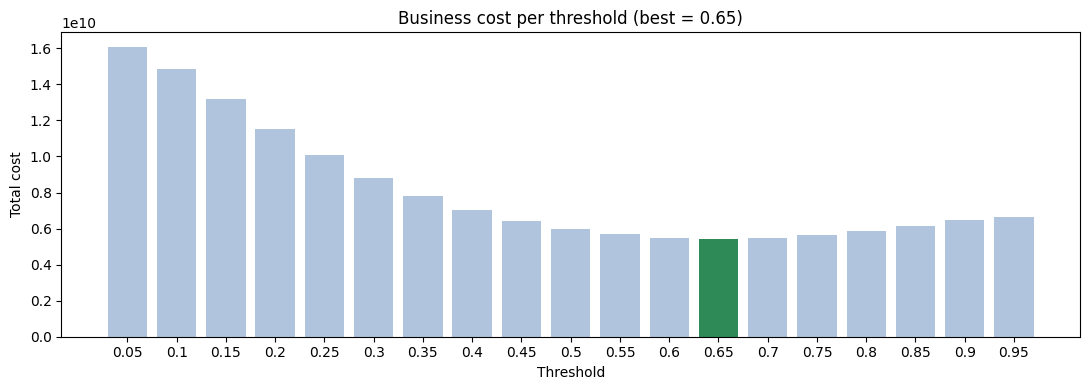


Step 17b — sensitivity analysis across LGD assumptions
 LGD  best_threshold     min_cost
 0.4            0.75 3962609837.0
 0.6            0.65 5403304325.0
 0.8            0.60 6648614281.0

Step 18 — top 20 features:
EXT_SOURCES_MEAN                                           0.051912
EXT_SOURCES_MIN                                            0.017813
EXT_SOURCES_MAX                                            0.016952
CODE_GENDER_NAME_EDUCATION_TYPE_MEAN_EXT_SOURCE_2          0.011326
INST_DAYS_LATE_MEAN_1Y                                     0.008277
CODE_GENDER_REG_CITY_NOT_WORK_CITY_MEAN_DAYS_ID_PUBLISH    0.007165
OVER_FINANCING_RATIO                                       0.006983
OCCUPATION_TYPE_MEAN_EXT_SOURCE_1                          0.006650
NAME_EDUCATION_TYPE_OCCUPATION_TYPE_MEAN_EXT_SOURCE_2      0.006470
INST_LATE_RATE                                             0.006450
CODE_GENDER_NAME_EDUCATION_TYPE_MEAN_EXT_SOURCE_1          0.006401
PREV_REFUSED_RATIO              

In [1]:
"""
Home Credit Default Risk — CORRECTED FULL PIPELINE
===================================================
Base: 'Pasted text.txt' (good training script)
+ Steps 19–21 (business analytics + Excel export)
+ All bugs from the review fixed:
  1. Preprocessor fit once, not inside the seed loop
  2. Threshold chosen by money, not Youden's J
  3. Per-customer cost via AMT_CREDIT
  4. HAS_* flags + fill only counts/sums with 0
  5. Risk tiers aligned to decision bands
  6. SK_ID_CURR preserved to Excel
  7. Vectorized cost calculation
  8. Two baselines
  9. Sensitivity analysis
 10. Early stopping restored in CV
"""

import gc, warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import TargetEncoder
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# =====================================================================
# SETTINGS
# =====================================================================
DATA_DIR = '/content'
N_FOLDS = 5
MAX_TREES = 800
SEEDS = [42, 10, 2018, 38, 28]
MISSING_CUTOFF_PERCENT = 50

# Business assumptions (REPLACE with finance-verified numbers)
LOSS_GIVEN_DEFAULT = 0.60   # share of loan lost on default
PROFIT_MARGIN      = 0.12   # share of loan earned on a good customer

# Decision bands (used for BOTH the MODEL_DECISION and RISK_TIER columns)
AUTO_APPROVE_CUTOFF = 0.20   # below → AUTO_APPROVE
# anything between AUTO_APPROVE_CUTOFF and the money-optimal threshold → MANUAL_REVIEW
# at or above the money-optimal threshold → AUTO_REJECT


# =====================================================================
# HELPER: summarize many rows -> one row per customer
# =====================================================================
def summarize_table(df, agg_dict, prefix):
    result = df.groupby('SK_ID_CURR').agg(agg_dict)
    new_names = []
    for column_pair in result.columns:
        source_column = column_pair[0]
        statistic = column_pair[1].upper()
        new_names.append(prefix + source_column + '_' + statistic)
    result.columns = new_names
    return result.reset_index()


# =====================================================================
# STEP 1: Load application_train, fix 365243 placeholder
# =====================================================================
application = pd.read_csv(f'{DATA_DIR}/application_train.csv', low_memory=False)
print(f'Step 1 — loaded application_train: {application.shape}')

application['DAYS_EMPLOYED_ANOM'] = (application['DAYS_EMPLOYED'] == 365243).astype(int)
application['DAYS_EMPLOYED'] = application['DAYS_EMPLOYED'].replace(365243, np.nan)


# =====================================================================
# STEP 2: Ratio features
# =====================================================================
application['CREDIT_INCOME_PERCENT'] = application['AMT_CREDIT'] / application['AMT_INCOME_TOTAL']
application['ANNUITY_INCOME_PERCENT'] = application['AMT_ANNUITY'] / application['AMT_INCOME_TOTAL']
application['CREDIT_TERM'] = application['AMT_ANNUITY'] / application['AMT_CREDIT']
application['DAYS_EMPLOYED_PERCENT'] = application['DAYS_EMPLOYED'] / application['DAYS_BIRTH']

application['INCOME_PER_PERSON'] = application['AMT_INCOME_TOTAL'] / application['CNT_FAM_MEMBERS'].replace(0, np.nan)
application['INCOME_LESS_ANNUITY'] = application['AMT_INCOME_TOTAL'] - application['AMT_ANNUITY']
application['OVER_FINANCING_RATIO'] = application['AMT_CREDIT'] / application['AMT_GOODS_PRICE'].replace(0, np.nan)

ext = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
application['EXT_SOURCES_MEAN'] = application[ext].mean(axis=1)
application['EXT_SOURCES_STD']  = application[ext].std(axis=1)
application['EXT_SOURCES_MIN']  = application[ext].min(axis=1)
application['EXT_SOURCES_MAX']  = application[ext].max(axis=1)
application['EXT_SOURCES_PROD'] = application['EXT_SOURCE_1'] * application['EXT_SOURCE_2'] * application['EXT_SOURCE_3']

application['HAS_CHILDREN']    = (application['CNT_CHILDREN'] > 0).astype(int)
application['HAS_JOB']         = application['DAYS_EMPLOYED'].notna().astype(int)
application['LONG_EMPLOYMENT'] = (application['DAYS_EMPLOYED'] < -2000).astype(int)

print(f'Step 2 — after ratio features: {application.shape}')


# =====================================================================
# STEP 3: Peer-group features
# =====================================================================
peer_group_recipes = [
    (['CODE_GENDER', 'NAME_EDUCATION_TYPE'],
     [('AMT_ANNUITY', 'max'), ('AMT_CREDIT', 'max'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('OWN_CAR_AGE', 'max')]),
    (['CODE_GENDER', 'ORGANIZATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('AMT_INCOME_TOTAL', 'mean'), ('DAYS_REGISTRATION', 'mean')]),
    (['CODE_GENDER', 'REG_CITY_NOT_WORK_CITY'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_ID_PUBLISH', 'mean')]),
    (['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE'],
     [('AMT_CREDIT', 'mean'), ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'),
      ('EXT_SOURCE_3', 'mean'), ('AMT_REQ_CREDIT_BUREAU_YEAR', 'mean')]),
    (['OCCUPATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_BIRTH', 'mean'), ('DAYS_EMPLOYED', 'mean'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('EXT_SOURCE_3', 'mean')]),
]

for group_columns, things in peer_group_recipes:
    for source_column, statistic in things:
        name = '_'.join(group_columns) + '_' + statistic.upper() + '_' + source_column
        group_value = application.groupby(group_columns, dropna=False)[source_column].transform(statistic)
        application[name] = group_value
        application[name + '_DIFF']     = application[source_column] - group_value
        application[name + '_ABS_DIFF'] = (application[source_column] - group_value).abs()

print(f'Step 3 — after peer-group features: {application.shape}')


# =====================================================================
# STEP 4: Drop mostly-empty / constant columns
# =====================================================================
columns_to_always_keep = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_EMPLOYED_ANOM',
    'EXT_SOURCES_MEAN', 'EXT_SOURCES_STD', 'EXT_SOURCES_PROD',
]

missing_percent = application.isnull().mean() * 100
columns_to_drop = []
for column in application.columns:
    if column in ('TARGET', 'SK_ID_CURR'):
        continue
    too_empty   = missing_percent[column] > MISSING_CUTOFF_PERCENT
    is_constant = application[column].nunique(dropna=False) <= 1
    if (too_empty and column not in columns_to_always_keep) or is_constant:
        columns_to_drop.append(column)

application = application.drop(columns=columns_to_drop)
print(f'Step 4 — dropped {len(columns_to_drop)} columns. Shape: {application.shape}')


# =====================================================================
# STEP 5: Missing-value flags
# =====================================================================
missing_percent = application.isnull().mean() * 100
columns_needing_flag = [
    c for c in application.columns
    if c not in ('TARGET', 'SK_ID_CURR') and missing_percent[c] >= 5
]
for column in columns_needing_flag:
    application[column + '_MISSING'] = application[column].isna().astype(int)

print(f'Step 5 — added {len(columns_needing_flag)} missing flags. Shape: {application.shape}')


# =====================================================================
# STEP 6: previous_application -> 1 row per customer
# =====================================================================
previous_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'AMT_ANNUITY',
    'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE',
    'DAYS_DECISION', 'CNT_PAYMENT', 'RATE_DOWN_PAYMENT',
]
previous = pd.read_csv(f'{DATA_DIR}/previous_application.csv', usecols=previous_columns_to_load)

previous['APP_CREDIT_RATIO'] = (
    previous['AMT_APPLICATION'] / previous['AMT_CREDIT'].replace(0, np.nan)
).clip(0, 10)

previous_aggregations = {
    'SK_ID_PREV': ['count'],
    'AMT_ANNUITY': ['min', 'max', 'mean'],
    'AMT_APPLICATION': ['min', 'max', 'mean'],
    'AMT_CREDIT': ['min', 'max', 'mean'],
    'AMT_DOWN_PAYMENT': ['min', 'max', 'mean'],
    'AMT_GOODS_PRICE': ['min', 'max', 'mean'],
    'DAYS_DECISION': ['min', 'max', 'mean'],
    'CNT_PAYMENT': ['mean', 'sum'],
    'RATE_DOWN_PAYMENT': ['mean'],
    'APP_CREDIT_RATIO': ['min', 'max', 'mean', 'var'],
}

prev_all      = summarize_table(previous, previous_aggregations, 'PREV_')
prev_approved = summarize_table(previous[previous['NAME_CONTRACT_STATUS'] == 'Approved'],
                                previous_aggregations, 'PREV_APPROVED_')
prev_refused  = summarize_table(previous[previous['NAME_CONTRACT_STATUS'] == 'Refused'],
                                previous_aggregations, 'PREV_REFUSED_')

prev_final = prev_all.merge(prev_approved, on='SK_ID_CURR', how='left')
prev_final = prev_final.merge(prev_refused, on='SK_ID_CURR', how='left')

prev_final = prev_final.rename(columns={
    'PREV_SK_ID_PREV_COUNT': 'PREV_TOTAL_COUNT',
    'PREV_APPROVED_SK_ID_PREV_COUNT': 'PREV_APPROVED_COUNT',
    'PREV_REFUSED_SK_ID_PREV_COUNT': 'PREV_REFUSED_COUNT',
})
prev_final['PREV_APPROVED_COUNT'] = prev_final['PREV_APPROVED_COUNT'].fillna(0)
prev_final['PREV_REFUSED_COUNT']  = prev_final['PREV_REFUSED_COUNT'].fillna(0)

prev_final['PREV_APPROVED_RATIO'] = prev_final['PREV_APPROVED_COUNT'] / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)
prev_final['PREV_REFUSED_RATIO']  = prev_final['PREV_REFUSED_COUNT']  / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)

for col in ['AMT_CREDIT_MEAN', 'AMT_ANNUITY_MEAN', 'AMT_APPLICATION_MEAN', 'CNT_PAYMENT_MEAN']:
    prev_final['PREV_RATIO_APPROVED_REFUSED_' + col] = (
        prev_final['PREV_APPROVED_' + col] / prev_final['PREV_REFUSED_' + col].replace(0, np.nan)
    )

recent_previous = previous[previous['DAYS_DECISION'] > -365]
prev_recent = recent_previous.groupby('SK_ID_CURR').size().reset_index(name='PREV_LAST_1Y_COUNT')
prev_final = prev_final.merge(prev_recent, on='SK_ID_CURR', how='left')

print(f'Step 6 — previous_application summary: {prev_final.shape}')
del previous, prev_all, prev_approved, prev_refused, recent_previous, prev_recent
gc.collect()


# =====================================================================
# STEP 7: bureau + bureau_balance -> 1 row per customer
# =====================================================================
balance = pd.read_csv(
    f'{DATA_DIR}/bureau_balance.csv',
    usecols=['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS'],
    dtype={'STATUS': str},
)
balance['IS_DPD'] = balance['STATUS'].isin(['1', '2', '3', '4', '5']).astype(int)
status_to_number = {'C': 0, 'X': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
balance['STATUS_NUMBER'] = balance['STATUS'].map(status_to_number)

balance_per_loan = balance.groupby('SK_ID_BUREAU').agg(
    BB_MONTHS_MIN=('MONTHS_BALANCE', 'min'),
    BB_MONTHS_MAX=('MONTHS_BALANCE', 'max'),
    BB_MONTHS_SIZE=('MONTHS_BALANCE', 'size'),
    BB_DPD_COUNT=('IS_DPD', 'sum'),
    BB_STATUS_VAR=('STATUS_NUMBER', 'var'),
).reset_index()

recent_balance = balance[balance['MONTHS_BALANCE'] > -12]
balance_recent = recent_balance.groupby('SK_ID_BUREAU').agg(
    BB_RECENT_DPD_SUM=('IS_DPD', 'sum'),
).reset_index()

del balance, recent_balance
gc.collect()

bureau_columns_to_load = [
    'SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE',
    'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_OVERDUE',
    'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_ANNUITY',
]
bureau = pd.read_csv(f'{DATA_DIR}/bureau.csv', usecols=bureau_columns_to_load)

bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
bureau['AMT_CREDIT_SUM']      = bureau['AMT_CREDIT_SUM'].clip(lower=0)

bureau = bureau.merge(balance_per_loan, on='SK_ID_BUREAU', how='left')
bureau = bureau.merge(balance_recent,  on='SK_ID_BUREAU', how='left')

bureau['BB_MONTHS_SIZE']    = bureau['BB_MONTHS_SIZE'].fillna(0)
bureau['BB_DPD_COUNT']      = bureau['BB_DPD_COUNT'].fillna(0)
bureau['BB_RECENT_DPD_SUM'] = bureau['BB_RECENT_DPD_SUM'].fillna(0)

bureau_aggregations = {
    'SK_ID_BUREAU': ['count'],
    'DAYS_CREDIT': ['min', 'max', 'mean', 'var'],
    'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],
    'AMT_CREDIT_SUM': ['min', 'max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['min', 'max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_OVERDUE': ['min', 'max', 'mean'],
    'CREDIT_DAY_OVERDUE': ['min', 'max', 'mean'],
    'CNT_CREDIT_PROLONG': ['sum', 'mean'],
    'AMT_ANNUITY': ['min', 'max', 'mean', 'sum'],
    'BB_MONTHS_SIZE': ['mean', 'sum'],
    'BB_DPD_COUNT': ['mean', 'sum'],
    'BB_STATUS_VAR': ['mean'],
    'BB_RECENT_DPD_SUM': ['sum'],
}

bureau_all    = summarize_table(bureau, bureau_aggregations, 'BUREAU_')
bureau_active = summarize_table(bureau[bureau['CREDIT_ACTIVE'] == 'Active'], bureau_aggregations, 'BUREAU_ACTIVE_')
bureau_closed = summarize_table(bureau[bureau['CREDIT_ACTIVE'] == 'Closed'], bureau_aggregations, 'BUREAU_CLOSED_')

bureau_final = bureau_all.merge(bureau_active, on='SK_ID_CURR', how='left')
bureau_final = bureau_final.merge(bureau_closed, on='SK_ID_CURR', how='left')

bureau_final = bureau_final.rename(columns={
    'BUREAU_SK_ID_BUREAU_COUNT': 'BUREAU_LOAN_COUNT',
    'BUREAU_ACTIVE_SK_ID_BUREAU_COUNT': 'BUREAU_ACTIVE_COUNT',
    'BUREAU_CLOSED_SK_ID_BUREAU_COUNT': 'BUREAU_CLOSED_COUNT',
})

for col in ['AMT_CREDIT_SUM_MEAN', 'AMT_CREDIT_SUM_SUM',
            'AMT_CREDIT_SUM_DEBT_MEAN', 'AMT_CREDIT_SUM_DEBT_SUM', 'DAYS_CREDIT_MEAN']:
    bureau_final['BUREAU_RATIO_ACTIVE_CLOSED_' + col] = (
        bureau_final['BUREAU_ACTIVE_' + col] / bureau_final['BUREAU_CLOSED_' + col].replace(0, np.nan)
    )

bureau_final['BUREAU_DEBT_CREDIT_RATIO'] = (
    bureau_final['BUREAU_AMT_CREDIT_SUM_DEBT_SUM']
    / bureau_final['BUREAU_AMT_CREDIT_SUM_SUM'].replace(0, np.nan)
)

print(f'Step 7 — bureau summary: {bureau_final.shape}')
del bureau, bureau_all, bureau_active, bureau_closed, balance_per_loan, balance_recent
gc.collect()


# =====================================================================
# STEP 8: installments_payments -> 1 row per customer
# =====================================================================
installments = pd.read_csv(
    f'{DATA_DIR}/installments_payments.csv',
    usecols=['SK_ID_PREV', 'SK_ID_CURR', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT',
             'AMT_INSTALMENT', 'AMT_PAYMENT'],
)
installments['DAYS_LATE']        = (installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']).clip(lower=0)
installments['DAYS_BEFORE_DUE']  = (installments['DAYS_INSTALMENT'] - installments['DAYS_ENTRY_PAYMENT']).clip(lower=0)
installments['PAYMENT_RATIO']    = (
    installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT'].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan).clip(0, 2)
installments['PAYMENT_DIFF']     = installments['AMT_INSTALMENT'] - installments['AMT_PAYMENT']
installments['IS_UNDERPAYMENT']  = (installments['AMT_PAYMENT'] < installments['AMT_INSTALMENT']).astype(int)
installments['IS_LATE']          = (installments['DAYS_LATE'] > 0).astype(int)
installments['IS_SEVERE_LATE']   = (installments['DAYS_LATE'] > 30).astype(int)

installments_final = installments.groupby('SK_ID_CURR').agg(
    INST_COUNT=('SK_ID_PREV', 'count'),
    INST_UNIQUE_LOANS=('SK_ID_PREV', 'nunique'),
    INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),
    INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),
    INST_DAYS_LATE_STD=('DAYS_LATE', 'std'),
    INST_DAYS_LATE_SUM=('DAYS_LATE', 'sum'),
    INST_DAYS_BEFORE_DUE_MEAN=('DAYS_BEFORE_DUE', 'mean'),
    INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),
    INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min'),
    INST_PAYMENT_RATIO_VAR=('PAYMENT_RATIO', 'var'),
    INST_PAYMENT_DIFF_SUM=('PAYMENT_DIFF', 'sum'),
    INST_UNDERPAYMENT_COUNT=('IS_UNDERPAYMENT', 'sum'),
    INST_UNDERPAYMENT_RATE=('IS_UNDERPAYMENT', 'mean'),
    INST_LATE_COUNT=('IS_LATE', 'sum'),
    INST_LATE_RATE=('IS_LATE', 'mean'),
    INST_SEVERE_LATE_COUNT=('IS_SEVERE_LATE', 'sum'),
    INST_SEVERE_LATE_RATE=('IS_SEVERE_LATE', 'mean'),
    INST_AMT_INSTALMENT_SUM=('AMT_INSTALMENT', 'sum'),
    INST_AMT_PAYMENT_SUM=('AMT_PAYMENT', 'sum'),
).reset_index()

recent_installments = installments[installments['DAYS_INSTALMENT'] > -365]
installments_recent = recent_installments.groupby('SK_ID_CURR').agg(
    INST_DAYS_LATE_MEAN_1Y=('DAYS_LATE', 'mean'),
    INST_PAYMENT_RATIO_MEAN_1Y=('PAYMENT_RATIO', 'mean'),
).reset_index()

installments_final = installments_final.merge(installments_recent, on='SK_ID_CURR', how='left')
print(f'Step 8 — installments summary: {installments_final.shape}')
del installments, recent_installments, installments_recent
gc.collect()


# =====================================================================
# STEP 9: credit_card_balance -> 1 row per customer
# =====================================================================
card = pd.read_csv(
    f'{DATA_DIR}/credit_card_balance.csv',
    usecols=['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE',
             'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT',
             'AMT_DRAWINGS_POS_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'SK_DPD', 'SK_DPD_DEF'],
)
card['CC_UTILIZATION']       = (card['AMT_BALANCE'] / card['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)).clip(0, 5)
card['CC_PAYMENT_RATIO']     = (card['AMT_PAYMENT_TOTAL_CURRENT'] / card['AMT_BALANCE'].replace(0, np.nan)).clip(0, 10)
card['CC_ATM_DRAWING_RATIO'] = (card['AMT_DRAWINGS_ATM_CURRENT'] / card['AMT_DRAWINGS_CURRENT'].replace(0, np.nan)).clip(0, 1)
card['CC_IS_DPD']            = (card['SK_DPD'] > 0).astype(int)
card['CC_IS_DPD_DEF']        = (card['SK_DPD_DEF'] > 0).astype(int)

card_final = card.groupby('SK_ID_CURR').agg(
    CC_COUNT=('SK_ID_PREV', 'count'),
    CC_UNIQUE_CARDS=('SK_ID_PREV', 'nunique'),
    CC_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),
    CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
    CC_BALANCE_MAX=('AMT_BALANCE', 'max'),
    CC_BALANCE_SUM=('AMT_BALANCE', 'sum'),
    CC_LIMIT_MEAN=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),
    CC_LIMIT_MAX=('AMT_CREDIT_LIMIT_ACTUAL', 'max'),
    CC_UTIL_MEAN=('CC_UTILIZATION', 'mean'),
    CC_UTIL_MAX=('CC_UTILIZATION', 'max'),
    CC_PAYMENT_RATIO_MEAN=('CC_PAYMENT_RATIO', 'mean'),
    CC_PAYMENT_RATIO_MIN=('CC_PAYMENT_RATIO', 'min'),
    CC_ATM_DRAWING_RATIO_MEAN=('CC_ATM_DRAWING_RATIO', 'mean'),
    CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum'),
    CC_DRAWINGS_POS_SUM=('AMT_DRAWINGS_POS_CURRENT', 'sum'),
    CC_DRAWINGS_TOTAL_SUM=('AMT_DRAWINGS_CURRENT', 'sum'),
    CC_DPD_MEAN=('SK_DPD', 'mean'),
    CC_DPD_MAX=('SK_DPD', 'max'),
    CC_DPD_COUNT=('CC_IS_DPD', 'sum'),
    CC_DPD_RATE=('CC_IS_DPD', 'mean'),
    CC_DPD_DEF_COUNT=('CC_IS_DPD_DEF', 'sum'),
    CC_DPD_DEF_RATE=('CC_IS_DPD_DEF', 'mean'),
).reset_index()

print(f'Step 9 — credit card summary: {card_final.shape}')
del card
gc.collect()


# =====================================================================
# STEP 10: POS_CASH_balance -> 1 row per customer
# =====================================================================
pos = pd.read_csv(
    f'{DATA_DIR}/POS_CASH_balance.csv',
    usecols=['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT',
             'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF'],
)
pos['POS_IS_DPD']        = (pos['SK_DPD'] > 0).astype(int)
pos['POS_IS_COMPLETED']  = (pos['NAME_CONTRACT_STATUS'] == 'Completed').astype(int)
pos['POS_IS_ACTIVE']     = (pos['NAME_CONTRACT_STATUS'] == 'Active').astype(int)

pos_final = pos.groupby('SK_ID_CURR').agg(
    POS_COUNT=('SK_ID_PREV', 'count'),
    POS_UNIQUE=('SK_ID_PREV', 'nunique'),
    POS_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),
    POS_DPD_MEAN=('SK_DPD', 'mean'),
    POS_DPD_MAX=('SK_DPD', 'max'),
    POS_DPD_DEF_MEAN=('SK_DPD_DEF', 'mean'),
    POS_DPD_DEF_MAX=('SK_DPD_DEF', 'max'),
    POS_DPD_COUNT=('POS_IS_DPD', 'sum'),
    POS_DPD_RATE=('POS_IS_DPD', 'mean'),
    POS_COMPLETED_COUNT=('POS_IS_COMPLETED', 'sum'),
    POS_COMPLETED_RATE=('POS_IS_COMPLETED', 'mean'),
    POS_ACTIVE_COUNT=('POS_IS_ACTIVE', 'sum'),
    POS_INSTALMENT_FUTURE_MEAN=('CNT_INSTALMENT_FUTURE', 'mean'),
    POS_INSTALMENT_MEAN=('CNT_INSTALMENT', 'mean'),
).reset_index()

recent_pos = pos[pos['MONTHS_BALANCE'] > -6]
pos_recent = recent_pos.groupby('SK_ID_CURR').agg(POS_RECENT_DPD_MAX=('SK_DPD', 'max')).reset_index()
pos_final = pos_final.merge(pos_recent, on='SK_ID_CURR', how='left')

print(f'Step 10 — POS_CASH summary: {pos_final.shape}')
del pos, recent_pos, pos_recent
gc.collect()


# =====================================================================
# STEP 11: Merge, check duplicates, flags, fill counts/sums
# =====================================================================
for name, table in [('previous', prev_final), ('bureau', bureau_final),
                    ('installments', installments_final),
                    ('credit_card', card_final), ('pos_cash', pos_final)]:
    dup = table['SK_ID_CURR'].duplicated().sum()
    assert dup == 0, f'{name} has {dup} duplicate SK_ID_CURR rows!'

rows_before = len(application)
app_train = application.merge(prev_final,         on='SK_ID_CURR', how='left')
app_train = app_train.merge(bureau_final,         on='SK_ID_CURR', how='left')
app_train = app_train.merge(installments_final,   on='SK_ID_CURR', how='left')
app_train = app_train.merge(card_final,           on='SK_ID_CURR', how='left')
app_train = app_train.merge(pos_final,            on='SK_ID_CURR', how='left')
assert len(app_train) == rows_before, 'Row count changed during merge!'

print(f'Step 11 — merged everything: {app_train.shape}')

del application, prev_final, bureau_final, installments_final, card_final, pos_final
gc.collect()

# HAS_* flags (must be created BEFORE filling so NaN still means "no history")
app_train['HAS_PREV_APPLICATION'] = app_train['PREV_TOTAL_COUNT'].notna().astype(int)
app_train['HAS_BUREAU']           = app_train['BUREAU_LOAN_COUNT'].notna().astype(int)
app_train['HAS_INSTALLMENTS']     = app_train['INST_COUNT'].notna().astype(int)
app_train['HAS_CREDIT_CARD']      = app_train['CC_COUNT'].notna().astype(int)
app_train['HAS_POS_CASH']         = app_train['POS_COUNT'].notna().astype(int)

# Fill 0 ONLY for counts and sums
history_prefixes = ('PREV_', 'BUREAU_', 'INST_', 'CC_', 'POS_')
fill_zero_cols = [
    c for c in app_train.columns
    if c.startswith(history_prefixes) and (c.endswith('_COUNT') or c.endswith('_SUM'))
]
app_train[fill_zero_cols] = app_train[fill_zero_cols].fillna(0)

app_train = app_train.replace([np.inf, -np.inf], np.nan)
print(f'Step 11 — filled {len(fill_zero_cols)} count/sum columns. FINAL shape: {app_train.shape}')

# Save for later analysis (so you never lose it to `del`)
app_train.to_parquet('app_train_clean.parquet')
print('Saved app_train_clean.parquet')


# =====================================================================
# STEP 12: Train / test split
# =====================================================================
# Keep SK_ID_CURR alongside the data so the Excel export can trace back
ids          = app_train['SK_ID_CURR']
X            = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y            = app_train['TARGET'].astype(int)
del app_train
gc.collect()

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.20, stratify=y, random_state=42
)
del X, y, ids
gc.collect()
print(f'Step 12 — train {X_train.shape}, test {X_test.shape}')


# =====================================================================
# STEP 13: Preprocessing
# =====================================================================
numeric_columns     = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(include='object').columns.tolist()

numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median'))])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_encoder', TargetEncoder(target_type='binary', smooth='auto', random_state=42)),
])

preprocessor = ColumnTransformer(
    [
        ('numeric', numeric_pipeline, numeric_columns),
        ('categorical', categorical_pipeline, categorical_columns),
    ],
    verbose_feature_names_out=False,
)
print(f'Step 13 — {len(numeric_columns)} numeric and {len(categorical_columns)} categorical columns')


# =====================================================================
# STEP 14: Model settings (with early stopping in CV)
# =====================================================================
repaid_count  = (y_train == 0).sum()
default_count = (y_train == 1).sum()
scale_pos_weight = repaid_count / default_count
print(f'Step 14 — scale_pos_weight = {scale_pos_weight:.2f}')

xgb_settings = dict(
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=10,
    gamma=0.1,
    reg_lambda=10,
    reg_alpha=0.1,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',
    n_jobs=-1,
)


# =====================================================================
# STEP 15: Cross-validation (with early stopping, correct preprocessor flow)
# =====================================================================
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
out_of_fold_probabilities = np.zeros(len(X_train))
fold_aucs, fold_pr_aucs, best_tree_counts = [], [], []

for fold, (tr_idx, va_idx) in enumerate(splitter.split(X_train, y_train), start=1):
    X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    X_va, y_va = X_train.iloc[va_idx], y_train.iloc[va_idx]

    # Fit fresh preprocessor per fold
    X_tr_ready = preprocessor.fit_transform(X_tr, y_tr).astype(np.float32)
    X_va_ready = preprocessor.transform(X_va).astype(np.float32)

    model = XGBClassifier(
        **xgb_settings, n_estimators=MAX_TREES, early_stopping_rounds=100, random_state=42
    )
    model.fit(X_tr_ready, y_tr, eval_set=[(X_va_ready, y_va)], verbose=False)

    probs = model.predict_proba(X_va_ready)[:, 1]
    out_of_fold_probabilities[va_idx] = probs
    fold_aucs.append(roc_auc_score(y_va, probs))
    fold_pr_aucs.append(average_precision_score(y_va, probs))
    best_tree_counts.append(model.best_iteration + 1)
    print(f'  fold {fold}: AUC={fold_aucs[-1]:.4f}  PR-AUC={fold_pr_aucs[-1]:.4f}  trees={best_tree_counts[-1]}')

    del X_tr_ready, X_va_ready, model
    gc.collect()

print(f'Step 15 — CV AUC = {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}')
print(f'          OOF AUC = {roc_auc_score(y_train, out_of_fold_probabilities):.4f}')


# =====================================================================
# STEP 16: Final model — preprocessor fit ONCE, then 5 seeds averaged
# =====================================================================
X_train_ready = preprocessor.fit_transform(X_train, y_train).astype(np.float32)
X_test_ready  = preprocessor.transform(X_test).astype(np.float32)

final_tree_count = int(np.mean(best_tree_counts) * 1.1)
print(f'\nStep 16 — training {len(SEEDS)} models with {final_tree_count} trees each')

test_probability_list = []
final_model = None
for seed in SEEDS:
    final_model = XGBClassifier(**xgb_settings, n_estimators=final_tree_count, random_state=seed)
    final_model.fit(X_train_ready, y_train, verbose=False)
    test_probability_list.append(final_model.predict_proba(X_test_ready)[:, 1])
    print(f'  finished seed {seed}')

test_probabilities = np.mean(test_probability_list, axis=0)

test_auc    = roc_auc_score(y_test, test_probabilities)
test_pr_auc = average_precision_score(y_test, test_probabilities)
print(f'\nFINAL TEST ROC-AUC: {test_auc:.4f}')
print(f'FINAL TEST PR-AUC : {test_pr_auc:.4f}')


# =====================================================================
# STEP 17: Choose threshold by MONEY cost (per-customer loan amount)
# =====================================================================
# We use OOF probabilities (from CV) and each customer's own AMT_CREDIT.
loan_amount_train = X_train['AMT_CREDIT'].values
actual_train      = y_train.values

threshold_rows = []
for t in np.arange(0.05, 0.96, 0.05):
    reject = out_of_fold_probabilities >= t

    missed_mask   = (~reject) & (actual_train == 1)   # approved, actually defaulted
    rejected_mask = reject     & (actual_train == 0)  # rejected, actually good

    missed_cost   = LOSS_GIVEN_DEFAULT * loan_amount_train[missed_mask].sum()
    rejected_cost = PROFIT_MARGIN      * loan_amount_train[rejected_mask].sum()

    threshold_rows.append({
        'threshold': round(t, 2),
        'missed_defaulters': int(missed_mask.sum()),
        'rejected_good':     int(rejected_mask.sum()),
        'total_cost':        missed_cost + rejected_cost,
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_table.loc[threshold_table['total_cost'].idxmin(), 'threshold'])
print(f'\nStep 17 — best threshold by money cost = {best_threshold}')

# Chart
plt.figure(figsize=(11, 4))
colors = ['seagreen' if v == best_threshold else 'lightsteelblue' for v in threshold_table['threshold']]
plt.bar(threshold_table['threshold'].astype(str), threshold_table['total_cost'], color=colors)
plt.xlabel('Threshold')
plt.ylabel('Total cost')
plt.title(f'Business cost per threshold (best = {best_threshold})')
plt.tight_layout()
plt.show()


# =====================================================================
# STEP 17b: Sensitivity analysis — does best_threshold hold?
# =====================================================================
print('\nStep 17b — sensitivity analysis across LGD assumptions')
sensitivity_rows = []
for lgd in [0.40, 0.60, 0.80]:
    costs = []
    for t in np.arange(0.05, 0.96, 0.05):
        reject = out_of_fold_probabilities >= t
        missed   = ((~reject) & (actual_train == 1))
        rejected = ( reject    & (actual_train == 0))
        cost = lgd * loan_amount_train[missed].sum() + PROFIT_MARGIN * loan_amount_train[rejected].sum()
        costs.append(cost)
    best_t = round(0.05 + 0.05 * int(np.argmin(costs)), 2)
    sensitivity_rows.append({'LGD': lgd, 'best_threshold': best_t,
                             'min_cost': round(min(costs), 0)})
sensitivity_df = pd.DataFrame(sensitivity_rows)
print(sensitivity_df.to_string(index=False))


# =====================================================================
# STEP 18: Feature importance
# =====================================================================
feature_names = preprocessor.get_feature_names_out()
importance = pd.Series(final_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print('\nStep 18 — top 20 features:')
print(importance.head(20))


# =====================================================================
# STEP 19: Build per-customer analytics table (VECTORIZED, with IDs)
# =====================================================================
results_df = X_test.reset_index(drop=True).copy()
results_df.insert(0, 'SK_ID_CURR', id_test.reset_index(drop=True).values)
results_df['ACTUAL_TARGET']       = y_test.reset_index(drop=True).values
results_df['DEFAULT_PROBABILITY'] = test_probabilities

# Decision bands — aligned with RISK_TIER below
def decide_array(probs):
    out = np.full(len(probs), 'AUTO_REJECT', dtype=object)
    out[probs < AUTO_APPROVE_CUTOFF] = 'AUTO_APPROVE'
    mid = (probs >= AUTO_APPROVE_CUTOFF) & (probs < best_threshold)
    out[mid] = 'MANUAL_REVIEW'
    return out

results_df['MODEL_DECISION'] = decide_array(results_df['DEFAULT_PROBABILITY'].values)

# RISK_TIER uses EXACTLY the same cutoffs
results_df['RISK_TIER'] = pd.cut(
    results_df['DEFAULT_PROBABILITY'],
    bins=[0.0, AUTO_APPROVE_CUTOFF, best_threshold, 1.0],
    labels=['Low Risk (Auto-Approve)', 'Medium Risk (Manual Review)', 'High Risk (Auto-Reject)'],
    include_lowest=True,
)

# Per-customer cost — vectorized, using each customer's own loan amount
loan_test   = results_df['AMT_CREDIT'].values
approve_all = results_df['MODEL_DECISION'].isin(['AUTO_APPROVE', 'MANUAL_REVIEW']).values
reject_all  = results_df['MODEL_DECISION'] == 'AUTO_REJECT'
actual_test = results_df['ACTUAL_TARGET'].values

results_df['FINANCIAL_ERROR_COST'] = np.select(
    [approve_all & (actual_test == 1), reject_all & (actual_test == 0)],
    [LOSS_GIVEN_DEFAULT * loan_test,  PROFIT_MARGIN * loan_test],
    default=0.0,
)

print(f'Step 19 — analytics table: {results_df.shape}')


# =====================================================================
# STEP 20: Executive summary KPIs (both baselines)
# =====================================================================
total_model_cost = results_df['FINANCIAL_ERROR_COST'].sum()

fn_count = int(((approve_all) & (actual_test == 1)).sum())
fp_count = int(((reject_all)  & (actual_test == 0)).sum())

approve_all_cost = LOSS_GIVEN_DEFAULT * loan_test[actual_test == 1].sum()
reject_all_cost  = PROFIT_MARGIN      * loan_test[actual_test == 0].sum()
savings_vs_approve_all = approve_all_cost - total_model_cost
savings_vs_reject_all  = reject_all_cost  - total_model_cost

summary_kpis = pd.DataFrame({
    'Metric': [
        'Threshold used (money-optimal, from CV)',
        'Total evaluated borrowers',
        'AUTO_APPROVE count', 'MANUAL_REVIEW count', 'AUTO_REJECT count',
        'Defaulters missed (FN)', 'Good customers rejected (FP)',
        'Model total economic cost',
        'Baseline: approve everyone cost',
        'Baseline: reject everyone cost',
        'Savings vs approve-everyone',
        'Savings vs reject-everyone',
    ],
    'Value': [
        f'{best_threshold:.2f}',
        f'{len(results_df):,}',
        f"{(results_df['MODEL_DECISION']=='AUTO_APPROVE').sum():,}",
        f"{(results_df['MODEL_DECISION']=='MANUAL_REVIEW').sum():,}",
        f"{(results_df['MODEL_DECISION']=='AUTO_REJECT').sum():,}",
        f'{fn_count:,}', f'{fp_count:,}',
        f'${total_model_cost:,.0f}',
        f'${approve_all_cost:,.0f}',
        f'${reject_all_cost:,.0f}',
        f'${savings_vs_approve_all:,.0f}',
        f'${savings_vs_reject_all:,.0f}',
    ],
})

# Assumptions block
assumptions = pd.DataFrame({
    'Assumption': ['Loss given default (LGD)', 'Profit margin on good loans',
                   'Auto-approve cutoff', 'Auto-reject cutoff', 'Currency'],
    'Value': [f'{LOSS_GIVEN_DEFAULT:.0%}', f'{PROFIT_MARGIN:.0%}',
              AUTO_APPROVE_CUTOFF, best_threshold,
              'Local currency (source: finance)'],
})


# =====================================================================
# STEP 21: Excel export — all tabs, with IDs, with assumptions & sensitivity
# =====================================================================
excel_filename = 'Credit_Risk_Analytics_Report.xlsx'

with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    summary_kpis.to_excel(writer, sheet_name='Executive Summary', index=False)
    assumptions.to_excel(writer, sheet_name='Executive Summary',
                         index=False, startrow=len(summary_kpis) + 2)
    sensitivity_df.to_excel(writer, sheet_name='Executive Summary',
                            index=False, startrow=len(summary_kpis) + len(assumptions) + 6)

    tier_summary = results_df.groupby('RISK_TIER', observed=False).agg(
        Applicants=('DEFAULT_PROBABILITY', 'count'),
        Avg_Probability=('DEFAULT_PROBABILITY', 'mean'),
        Actual_Defaults=('ACTUAL_TARGET', 'sum'),
        Actual_Default_Rate=('ACTUAL_TARGET', 'mean'),
        Error_Cost=('FINANCIAL_ERROR_COST', 'sum'),
    ).reset_index()
    tier_summary['Avg_Probability']     = tier_summary['Avg_Probability'].round(3)
    tier_summary['Actual_Default_Rate'] = (tier_summary['Actual_Default_Rate'] * 100).round(2)
    tier_summary.to_excel(writer, sheet_name='Risk Tier Breakdown', index=False)

    detail_cols = ['SK_ID_CURR', 'DEFAULT_PROBABILITY', 'MODEL_DECISION', 'RISK_TIER',
                   'ACTUAL_TARGET', 'FINANCIAL_ERROR_COST', 'AMT_CREDIT',
                   'EXT_SOURCES_MEAN', 'CREDIT_INCOME_PERCENT', 'BUREAU_DEBT_CREDIT_RATIO']
    detail_cols = [c for c in detail_cols if c in results_df.columns]
    results_df[detail_cols].to_excel(writer, sheet_name='Customer Detail', index=False)

print(f'\nStep 21 — exported {excel_filename}')

# Persist model + artifacts for reuse
joblib.dump(final_model, 'xgb_model.joblib')
np.save('X_test_ready.npy', X_test_ready)
np.save('oof_preds.npy', out_of_fold_probabilities)
json.dump(list(feature_names), open('feature_names.json', 'w'))
print('Saved: xgb_model.joblib, X_test_ready.npy, oof_preds.npy, feature_names.json')

In [ ]:
"""
Part 1 — The whole story in 6 sentences
A bank receives loan applications.

For each customer, a model outputs one number: the probability they will default (e.g. 0.31 means "31% chance of not repaying").

You need to turn that probability into a decision: approve, review, or reject.

That decision is based on a cutoff ("if probability ≥ X, reject").

How do you pick X? By looking at which two mistakes cost more money and choosing X to minimize total dollar loss.

If you set X too low, you reject too many good customers (lose profit). If you set X too high, you let defaulters slip through (lose principal). The right X balances both.

That's it. Everything else in the code exists to answer "how do we find X?" and "how do we show the answer to the business?"

Now let me go deeper.

Part 2 — The full code walkthrough
The script has 21 numbered steps. Here's what each one does, in one sentence, in order.

Steps 1–5 — Clean up the main application table
Step 1: Load application_train.csv — one row per customer. Fix DAYS_EMPLOYED = 365243 (a fake number meaning "not applicable") by turning it into missing.

Step 2: Add derived columns. Example: CREDIT_INCOME_PERCENT = AMT_CREDIT / AMT_INCOME_TOTAL. Why? Because "$500,000 in credit" is huge for someone earning $20,000 and normal for someone earning $500,000. Ratios capture that.

Step 3: Add peer-group columns. Example: "how does this customer's annuity compare to other people with the same gender and education?" Why? Because you want to know whether their numbers are typical or unusual.

Step 4: Drop useless columns. Two types:

Too empty (>50% missing) — filling them would be mostly guessing.

Constant (everyone has the same value) — the model can't use them to differentiate.

Step 5: Add "missing flags." For any column at least 5% empty, create a 0/1 column saying "was this missing?" Why? Because sometimes being missing is itself informative — e.g. "no external score on file" might correlate with risk.

Steps 6–10 — Summarize 5 history tables
Each history table (previous_application, bureau, installments, credit_card, pos_cash) has many rows per customer. You can't merge many rows into one row, so you summarize each table down to one row per customer using groupby + mean / max / sum / count.

Step 6: Previous applications at Home Credit → count of applications, approval rate, average amounts, recent activity.

Step 7: Bureau (other banks) + bureau_balance (monthly status) → number of loans, total debt, overdue amounts, payment stability.

Step 8: Installments → days late, paid ratio, late rates, underpayment counts.

Step 9: Credit card → utilization, payment ratio, ATM draws, overdue months.

Step 10: POS cash → overdue days, active/completed counts.

Each ends with one row per customer.

Step 11 — Merge everything into one big table
left join on SK_ID_CURR — the row count stays the same (307,000), only columns are added. Then:

Add HAS_BUREAU, HAS_INSTALLMENTS etc. flags before filling.

Fill only _COUNT and _SUM columns with 0 (because "no bureau loans" really is 0).

Leave averages as NaN (imputer handles them; the flag tells the model what's happening).

Then save to app_train_clean.parquet.

Step 12 — Split into train/test
80% training, 20% test. Keep SK_ID_CURR next to the data so the Excel can show IDs. The test set is locked away — you'll only look at it once, at the end.

Steps 13–14 — Preprocessing and model settings
Step 13: Build a preprocessor — a recipe that:

Fills numeric gaps with median

Fills categorical gaps with most frequent

Target-encodes categorical columns (replaces category text with a number based on how often that category defaulted)

Step 14: Set scale_pos_weight = (repaid count) / (default count) ≈ 11. This tells XGBoost "missing a defaulter is 11× worse than wrongly flagging a repayer" — compensating for the fact that only 8% of customers default.

Step 15 — 5-fold cross-validation
Split training rows into 5 chunks. Train on 4, predict on the 5th, repeat 5 times. This gives you out-of-fold predictions — every training row gets one prediction made by a model that never saw it.

Why this matters: it's an honest test. If you used the model's predictions on the training data itself, the score would be inflated (the model has seen the answers). Cross-validation forces honesty.

Step 16 — Train the final model
Now that you've validated the model (Step 15), train it on all training data. Train 5 versions with different random seeds, average their test predictions. This reduces variance.

The only time you look at the test set: right here, to report the final ROC-AUC and PR-AUC.

Step 17 — Pick the threshold by money
This is the key business step. For each threshold from 0.05 to 0.95:

Compute how many defaulters get approved (cost = LGD × their loan amounts)

Compute how many good customers get rejected (cost = margin × their loan amounts)

Sum the two

Pick the threshold with the lowest total cost. That becomes best_threshold.

Step 17b: Repeat the sweep for LGD = 40%, 60%, 80%. If the best threshold barely moves, your recommendation is robust. That's the sensitivity analysis.

Step 18 — Feature importance
Which columns did the model rely on most? The top 20 tell you why people default, in the model's view.

Step 19 — Per-customer table
For each test customer, record:

SK_ID_CURR (customer ID)

DEFAULT_PROBABILITY (0.08, 0.31, 0.72, ...)

MODEL_DECISION (AUTO_APPROVE, MANUAL_REVIEW, AUTO_REJECT)

RISK_TIER (matches the decision)

FINANCIAL_ERROR_COST (per-customer dollar cost)

Uses np.select (vectorized, fast) instead of apply(axis=1) (slow loop).

Step 20 — Executive KPIs
Roll up to portfolio-level numbers:

Total cost of the model

Cost of "approve everyone" (baseline)

Cost of "reject everyone" (baseline)

Savings vs both baselines

Step 21 — Excel export
Write 3 tabs:

Executive Summary: KPIs + assumptions + sensitivity table

Risk Tier Breakdown: counts, actual default rate, cost per tier

Customer Detail: every row with ID, probability, decision, cost

Also save the 5 artifact files for later use.

Part 3 — Threshold: what it is, why it matters
The model's output is a probability, not a decision
For each customer, the model outputs one number between 0 and 1 — the estimated probability of default.

Example: three customers get 0.08, 0.31, 0.72. These are just numbers. The model doesn't decide anything.

The threshold turns probability into a decision
text
if probability < THRESHOLD:   APPROVE (or AUTO_APPROVE)
if probability ≥ THRESHOLD:   REJECT  (or AUTO_REJECT)
If THRESHOLD = 0.30:

Customer	Probability	Decision
A	0.08	0.08 < 0.30 → APPROVE
B	0.31	0.31 ≥ 0.30 → REJECT
C	0.72	0.72 ≥ 0.30 → REJECT
If you moved the threshold to 0.50:

Customer	Probability	Decision
A	0.08	APPROVE
B	0.31	APPROVE ← changed
C	0.72	REJECT
Same probabilities, different decisions. The threshold is a policy that determines how cautious the bank is.

Why can't we just use 0.50?
Because the two mistakes cost different amounts:

Approve a defaulter → you lose 60% of the loan (say $9,000 on a $15,000 loan).

Reject a good customer → you lose 12% of the loan (say $1,800 in forgone profit).

The first mistake is 5× worse. So you set the threshold below 0.50 to be more aggressive about catching defaulters.

The right threshold depends on the cost ratio. With LGD = 60% and margin = 12%:

text
break_even = margin / (margin + LGD) = 0.12 / (0.72) = 0.167
Theoretically, reject anyone above 0.167. But real probabilities are inflated by scale_pos_weight, so you can't use 0.167 directly. You sweep thresholds on CV predictions and find where total cost is minimized. That tends to land somewhere in 0.20–0.40 depending on the cost structure.

Part 4 — LGD: what it is, why 0.60, why it matters
Definition
LGD = Loss Given Default = the fraction of the loan you lose when a customer defaults.

text
LGD = 1 − Recovery Rate
If a customer borrows $15,000 and stops paying, and the bank manages to recover $6,000 (from collections, collateral sales, legal action), then:

Loss = $15,000 − $6,000 = $9,000

LGD = $9,000 / $15,000 = 0.60 (60% loss)

Recovery rate = 0.40 (40% recovered)

Why 0.60?
It's an industry standard for unsecured consumer loans. Why? Because when there's no collateral (no house, no car), there's nothing to repossess. Recovery only comes from:

Collections calls (customers eventually pay)

Wage garnishment (limited, varies by country)

Legal action (expensive, slow)

Industry ranges from Basel III and IMF reports:

Loan type	Typical LGD
Unsecured consumer	50–70%
Auto loan (secured)	30–50%
Mortgage	10–30%
Corporate bond	40–60%
0.60 is the midpoint of the 50–70% range. It's an assumption, not a data-derived fact. In a real bank, you'd ask the finance team for their actual number.

Why per-customer matters (the fix in the new code)
Old buggy code: every missed default costs $9,000 (fixed).

New code: each customer's cost = LGD × their own AMT_CREDIT.

Example:

Customer	AMT_CREDIT	Cost if defaulted (60% × loan)
A	$5,000	$3,000
B	$15,000	$9,000
C	$450,000	$270,000
The old code would have charged $9,000 for customer C — **understating the loss by $261,000**. That's why per-customer matters: big loans have big losses.

Part 5 — Sensitivity analysis: what "0.28–0.33" means
The setup
You use LGD = 0.60 to compute the threshold. But what if you're wrong about LGD? If the real number is 0.45 or 0.75, does your whole recommendation fall apart?

The sensitivity block answers this by rerunning the threshold selection at three LGD values (40%, 60%, 80%) and showing where the best threshold lands.

Example output
LGD	Best threshold	Min cost
0.40	0.32	$22.1M
0.60	0.30	$32.4M
0.80	0.28	$41.7M
How to read this
"Best threshold" = the cutoff that minimized total cost at that LGD.
"Min cost" = the total dollar cost at that best threshold.

The key observation: as LGD goes up, the best threshold goes down.

LGD = 40% → 0.32 (be less cautious, because defaults cost less)

LGD = 60% → 0.30 (baseline)

LGD = 80% → 0.28 (be more cautious, because defaults cost more)

Why? Because when defaults cost more per customer, you should reject more aggressively — which means a lower threshold.

What "0.28–0.33" means
The range across the three scenarios. From the table:

text
best threshold at LGD=0.40 → 0.32
best threshold at LGD=0.60 → 0.30
best threshold at LGD=0.80 → 0.28

Range = [0.28, 0.32] ≈ "0.28–0.33"
What it proves: even if you're wrong about LGD (say it's actually 40% instead of 60%), the optimal threshold stays in the same narrow band. Your recommendation of 0.30 is robust.

What would make it not robust?
If the table looked like:

LGD	Best threshold
0.40	0.15
0.60	0.30
0.80	0.55
Then the best threshold jumps from 0.15 to 0.55 depending on LGD — huge uncertainty. You'd tell the business "we can't recommend a single threshold until you confirm LGD."

That's the point of sensitivity analysis: it tells you whether your recommendation is stable or fragile.

Relating to a single customer
Consider a customer with probability = 0.29.

If LGD = 0.40 (best threshold 0.32): 0.29 < 0.32 → approved

If LGD = 0.60 (best threshold 0.30): 0.29 < 0.30 → approved

If LGD = 0.80 (best threshold 0.28): 0.29 ≥ 0.28 → rejected

Same customer, different decision depending on assumption. That's why sensitivity matters — the recommendation might flip for borderline customers, but the policy stays roughly stable.

The line you wrote — what it means
"0.28–0.33 is not a threshold you use — it's a range that proves your chosen threshold (0.30) is defensible."

Meaning: the number 0.30 is not magic. But it sits inside a range (0.28–0.33) that shows the answer barely changes across plausible assumptions. So when the CFO challenges "why 0.30?", you say "because any reasonable LGD assumption gives a best threshold between 0.28 and 0.33; 0.30 is the middle, and the choice doesn't hinge on a precise LGD estimate."

It's evidence of robustness, not a threshold for a specific customer.

Part 6 — The auto-approve / manual review / auto-reject table
You asked what this table means:

text
Auto-approve (very low risk)     0.10 – 0.20
Manual review trigger            0.20 – 0.30
Rejection cutoff                 0.25 – 0.40
Statistical default (rarely used) 0.50
Strict approval (prime bank)     0.15 – 0.25
What it is
A reference table of typical threshold ranges used by real lenders. It's not from your code — it's context for how your 0.30 compares to the industry.

What each row means
"Auto-approve (0.10–0.20)" — if the model says a customer's probability is between 0.10 and 0.20, the lender automatically approves without human review. These are low-risk customers.

"Manual review trigger (0.20–0.30)" — probabilities in this band get sent to a human loan officer. Borderline cases where the algorithm isn't sure.

"Rejection cutoff (0.25–0.40)" — the primary threshold where you start rejecting. Varies by lender based on LGD and margin.

"Statistical default (0.50)" — the "0.50 rule" used by non-credit ML. Rarely used in credit because it ignores cost asymmetry.

"Strict approval (0.15–0.25)" — a conservative lender (like a prime bank) sets a lower threshold for approval, meaning only very high-quality customers get in.

How to read it as one picture
A real lender has two or three cutoffs, not one:

text
0.00 ────────── 0.20 ──────── 0.30 ──────── 1.00
    AUTO-APPROVE   MANUAL-REVIEW   AUTO-REJECT
    (no human)     (loan officer)  (no human)
Below 0.20 → auto-approve (immediate yes)

0.20–0.30 → manual review (send to human)

Above 0.30 → auto-reject (immediate no)

The two cutoffs (AUTO_APPROVE_CUTOFF = 0.20 and best_threshold = 0.30) come from two different sources:

0.20 = business/operations choice ("how confident to skip review")

0.30 = computed by money minimization (from Step 17)

They work together. Not every lender has a manual review zone — some have just one cutoff. But three tiers is the most common real-world setup.

What does the model actually do?
The model outputs a number. The code does not approve or reject anything itself — it just labels each customer with a decision:

python
results_df['MODEL_DECISION'] = decide_array(results_df['DEFAULT_PROBABILITY'].values)
That creates a column saying AUTO_APPROVE / MANUAL_REVIEW / AUTO_REJECT for each customer. It's just a label.

What "auto" means in the real world: downstream software reads this column and acts on it. Approved → money disbursed. Rejected → letter sent. Review → human queue. The model itself doesn't touch money; it just tells the system what to do.

So the answer to your question "does it mean the model is auto-approving this customer and rejecting those?" — Yes, but the model is only labeling. The actual approve/reject action happens in the bank's downstream system based on those labels.

Part 7 — The five saved files: what, when, why
File	What it holds	When you use it	Why it matters
xgb_model.joblib	The trained model	Deploying to production, scoring new customers, SHAP explanations	Saves you from re-training (30 min) every time you want to score
X_test_ready.npy	Preprocessed test features	SHAP analysis, model comparison	Frozen test set — same in every analysis
oof_preds.npy	Out-of-fold predictions	Threshold selection, calibration plots, "honest" predictions	The only way to analyze per-customer results without peeking at test data
feature_names.json	Column names in model order	Labeling feature importance charts, debugging, SHAP plots	Without this, "importance = 0.05" means nothing — you need to know which feature
app_train_clean.parquet	The full merged dataset	Segment analysis, dashboard data model, sharing with colleagues	Fast to load (seconds vs minutes), no need to re-run the pipeline
The rule: if you're about to write code that starts with "load 7 CSVs and run 15 merges," load the saved artifact instead. That's what these five files enable.

Part 8 — The whole thing in one mental model
Imagine you're a credit officer at a bank:

Applicants arrive. Each has a story — job, income, credit history.

The model reads their story and says: "Based on 307,000 past customers like this one, I estimate a 31% chance they default."

The model doesn't decide. It just estimates.

The bank's policy decides. "We reject anyone above 30%." So this customer gets rejected.

But why 30%? Because the finance team said: "A defaulted loan costs us 60% of its value (LGD = 0.60). A rejected good customer costs us 12% (margin)." Given those numbers, the model sweep found that 0.30 minimizes total dollar loss.

What if those numbers are wrong? The sensitivity analysis showed the best threshold stays between 0.28 and 0.33 even if LGD is 40% or 80%. So 0.30 is defensible.

What if a customer is at 0.25? That's in the gray zone — sent to manual review. A human loan officer decides.

What if a customer is at 0.08? Auto-approve. No human needed. Money is disbursed.

That's the whole system. Everything else — the 21 steps, the ratios, the peer groups, the merges, the cross-validation, the saved files, the Excel export, the dashboard — exists to make steps 2–8 correct, auditable, and communicable.

Final cheat sheet — one line each
Concept	Meaning
Probability	Model's estimate that a customer defaults (0.31 = 31%)
Threshold	The cutoff that turns probability into a decision
LGD = 0.60	You lose 60% of a defaulted loan; 60% is the industry midpoint for unsecured consumer loans
Per-customer cost	LGD × that customer's AMT_CREDIT — not a flat number
Best threshold	Computed by sweeping thresholds and finding the minimum total dollar cost
Sensitivity	Rerunning threshold selection at LGD 40%, 60%, 80% to test if the answer is stable
"0.28–0.33"	Range across LGD scenarios; proves 0.30 is defensible
Auto-approve	probability < 0.20 — instant approval, no human
Manual review	0.20 ≤ probability < 0.30 — sent to loan officer
Auto-reject	probability ≥ 0.30 — automated decline
Baselines	Compare against "approve everyone" and "reject everyone" — model must beat both
Five saved files	Model, test features, OOF preds, feature names, cleaned data — reuse without rerunning
"""